In [1]:
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)

METHOD = "hmm_pomegranate"


# 1. Read data

In [2]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
DATA_PATH_IMMUNOGENIC = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/immunogenic/per_length_per_kfold_split/' # windows

# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu

TARGET_PATH_TO_RESULTS = "experiment_results/"
# TARGET_PATH_TO_RESULTS = "experiment_results/backup/"


In [3]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")



per_allele_per_kfold_per_length_immunogenic_train = read_data(DATA_PATH_IMMUNOGENIC, ALLELES, "train", "immunogenic")
per_allele_per_kfold_per_length_immunogenic_test = read_data(DATA_PATH_IMMUNOGENIC, ALLELES, "test", "immunogenic")
per_allele_per_kfold_per_length_non_immunogenic_train = read_data(DATA_PATH_IMMUNOGENIC, ALLELES, "train", "nonimmunogenic")
per_allele_per_kfold_per_length_non_immunogenic_test = read_data(DATA_PATH_IMMUNOGENIC, ALLELES, "test", "nonimmunogenic")

ALLELES

['HLA-A*02:01']

# 2. Read models

In [4]:
from hmm_logic_methods import load_model

In [5]:
split_num = 1
run_num = 0
target_length = 9

selected_binding = f"{run_num}_run-{target_length}-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-{split_num}"
selected_immunogenic = f"{run_num}_run_imm-{target_length}-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-{split_num}"

MODEL_PATH_USED_IMMUNOGENIC = f"{TARGET_PATH_TO_RESULTS}{selected_immunogenic}/"
MODEL_PATH_USED_BINNDING = f"{TARGET_PATH_TO_RESULTS}{selected_binding}/"

model_immunogenic = load_model(TARGET_PATH_TO_RESULTS, selected_immunogenic)
model_binding = load_model(TARGET_PATH_TO_RESULTS, selected_binding)

train_peptides_immunogenic = per_allele_per_kfold_per_length_immunogenic_train[ALLELES[0]][split_num][target_length]
train_peptides_non_immunogenic = per_allele_per_kfold_per_length_non_immunogenic_train[ALLELES[0]][split_num][target_length]

train_peptides_binding = per_allele_per_kfold_per_length_binders_train[ALLELES[0]][split_num][target_length]
train_peptides_non_binding = per_allele_per_kfold_per_length_non_binders_train[ALLELES[0]][split_num][target_length]


test_peptides_immunogenic = per_allele_per_kfold_per_length_immunogenic_test[ALLELES[0]][split_num][target_length]
test_peptides_non_immunogenic = per_allele_per_kfold_per_length_non_immunogenic_test[ALLELES[0]][split_num][target_length]
test_peptides_binding = per_allele_per_kfold_per_length_binders_test[ALLELES[0]][split_num][target_length]
test_peptides_non_binding = per_allele_per_kfold_per_length_non_binders_test[ALLELES[0]][split_num][target_length]


# Generate most probable paths

In [6]:
from hmm_visualization_methods import convert_graph_to_good_format
import networkx as nx
import pandas as pd
import numpy as np

# Calculate probs for paths

In [7]:
def get_all_paths_with_probs(model, edge_value="log_probability"):
    df = pd.DataFrame(columns=["path", "prob"])
    # remove empty nodes (for speed up and only possible paths)
    new_graph, name_to_level = convert_graph_to_good_format(model,"", False, precision=4, edge_value=edge_value)
    paths = list(nx.all_simple_paths(new_graph, model.start.name, model.end.name)) # Might be very slow
    print(f"found {len(paths)} paths")
    edge_to_prob = dict()
    for path in paths:
        prob_for_path = 0 if edge_value == "log_probability" else 1
        path_edges = path.copy()
        node_from = path_edges.pop(0)
        while path_edges:
            node_to = path_edges.pop(0)
            edge = new_graph.get_edge_data(node_from, node_to)
            edge_to_prob[(node_from, node_to)] = edge['label']
            if edge_value == "log_probability":
                prob_for_path = prob_for_path + edge['label']
            else:
                prob_for_path = prob_for_path * edge['label']
            # print(f"edge {edge}")
            node_from = node_to
        # print(f"Total prob for path is {prob_for_path}")
        row = {"path": path, "prob": prob_for_path}
        df = df.append(row, ignore_index=True)
    df = df.sort_values('prob', ascending=False)
    print("Take top 50 most probable paths")
    df = df.head(50)
    return df, edge_to_prob

df_b, edge_to_prob_b = get_all_paths_with_probs(model_binding)
df_i, edge_to_prob_i = get_all_paths_with_probs(model_immunogenic)

Model: 0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1
{'0_run-9_model-start': 1, 's7_9': 2, 's9_9': 2, 's2_9': 3, 's8_9': 3, 's12_9': 3, 's5_9': 4, 's6_9': 5, 's17_9': 5, 's1_9': 6, 's13_9': 7, 's3_9': 8, 's11_9': 8, 's14_9': 8, 's0_9': 9, 's10_9': 9, 's15_9': 10, '0_run-9_model-end': 11, 's4_9': 4, 's16_9': 4}
found 84 paths
Take top 50 most probable paths
Model: 0_run_imm-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1
{'0_run_imm-9_model-start': 1, 's4_lengths_string': 2, 's14_lengths_string': 2, 's17_lengths_string': 2, 's5_lengths_string': 3, 's3_lengths_string': 4, 's12_lengths_string': 4, 's11_lengths_string': 5, 's15_lengths_string': 5, 's2_lengths_string': 6, 's6_lengths_string': 7, 's9_lengths_string': 7, 's10_lengths_string': 8, 's16_lengths_string': 8, 's1_lengths_string': 9, 's13_lengths_string': 9, 's0_lengths_string': 10, 's7_lengths_string': 10, '0_run_imm-9_model-end': 11, 's8_lengths_string': 6}
found 90 paths
Take top 50 most probable paths


In [8]:
df_b

,path,prob
66,"[0_run-9_model-start, s9_9, s8_9, s16_9, s6_9,...",-1.889703
71,"[0_run-9_model-start, s9_9, s8_9, s16_9, s6_9,...",-2.097722
67,"[0_run-9_model-start, s9_9, s8_9, s16_9, s6_9,...",-2.572273
69,"[0_run-9_model-start, s9_9, s8_9, s16_9, s6_9,...",-2.592210
70,"[0_run-9_model-start, s9_9, s8_9, s16_9, s6_9,...",-2.648270
54,"[0_run-9_model-start, s9_9, s8_9, s4_9, s6_9, ...",-3.333382
59,"[0_run-9_model-start, s9_9, s8_9, s4_9, s6_9, ...",-3.541402
36,"[0_run-9_model-start, s7_9, s12_9, s5_9, s17_9...",-3.580414
60,"[0_run-9_model-start, s9_9, s8_9, s4_9, s17_9,...",-3.633236
41,"[0_run-9_model-start, s7_9, s12_9, s5_9, s17_9...",-3.788433


In [9]:
def get_state_for_name(model, state_name):
    state = [state for state in model.states if state.name == state_name][0]
    return state

In [10]:
def get_prob_for_path_and_sequence(model,edge_to_prob, state_path, sequence, edge_value="log_probability"):
    prob_for_path = 0 if edge_value == "log_probability" else 1
    path_nodes = state_path.copy()
    node_from = path_nodes.pop(0)
    emissions = list(sequence)
    while path_nodes:
        node_to = path_nodes.pop(0)
        tr_prob = edge_to_prob[(node_from.name, node_to.name)]
        if node_from.name != model.start.name:
            emission = emissions.pop(0)
            e_prob = node_from.distribution.parameters[0][emission]
            e_prob = np.log(e_prob) if edge_value == "log_probability" else e_prob
            if edge_value == "log_probability":
                prob_for_path = prob_for_path + e_prob + tr_prob
            else:
                prob_for_path = prob_for_path * e_prob * tr_prob

        else:
            if edge_value == "log_probability":
                prob_for_path =  prob_for_path + tr_prob
            else:
                prob_for_path =  prob_for_path * tr_prob
        # print(f"edge {edge}")
        node_from = node_to
    return prob_for_path


In [11]:
def get_peptide_to_paths_df(model, peptides, edge_value="log_probability"):
    paths_df, edge_to_prob = get_all_paths_with_probs(model, edge_value=edge_value)
    # df = pd.DataFrame(columns=["peptide", "path", "prob"])
    result_peptides = []
    result_paths = []
    result_probs = []
    for peptide in peptides:
        for path in paths_df['path']:
            state_path = [get_state_for_name(model, state_name) for state_name in path]
            prob_for_path = get_prob_for_path_and_sequence(model, edge_to_prob, state_path, peptide, edge_value=edge_value)
            result_peptides.append(peptide)
            result_paths.append(path)
            result_probs.append(prob_for_path)
    df = pd.DataFrame({"peptide": result_peptides, "path":result_paths, "prob":result_probs})
    if edge_value == "log_probability":
        df.replace([-np.inf], -50000, inplace=True)
    return df



## Get DF for different data

In [12]:
generated_peptides_b = ["".join(model_binding.sample()) for i in range(2000)]
generated_peptides_i = ["".join(model_immunogenic.sample()) for i in range(2000)]

In [13]:
%%time
train_peptides_data_b_model_b = get_peptide_to_paths_df(model_binding, set(train_peptides_binding), edge_value="log_probability")
train_peptides_data_b_model_i = get_peptide_to_paths_df(model_immunogenic, set(train_peptides_binding), edge_value="log_probability")
train_peptides_data_i_model_b = get_peptide_to_paths_df(model_binding, set(train_peptides_immunogenic), edge_value="log_probability")
train_peptides_data_i_model_i = get_peptide_to_paths_df(model_immunogenic, set(train_peptides_immunogenic), edge_value="log_probability")

# train_peptides_data_nb_model_b = get_peptide_to_paths_df(model_binding, set(train_peptides_non_binding), edge_value="log_probability")
# train_peptides_data_nb_model_i = get_peptide_to_paths_df(model_immunogenic, set(train_peptides_non_binding), edge_value="log_probability")

# train_peptides_data_ni_model_b = get_peptide_to_paths_df(model_binding, set(train_peptides_non_immunogenic), edge_value="log_probability")
# train_peptides_data_b_model_i = get_peptide_to_paths_df(model_immunogenic, set(train_peptides_non_immunogenic), edge_value="log_probability")



# train_peptide_df_b = get_peptide_to_paths_df(model, set(train_peptides), edge_value="log_probability")
# train_peptide_df_i = get_peptide_to_paths_df(model, set(train_peptides), edge_value="log_probability")


Model: 0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1
{'0_run-9_model-start': 1, 's7_9': 2, 's9_9': 2, 's2_9': 3, 's8_9': 3, 's12_9': 3, 's5_9': 4, 's6_9': 5, 's17_9': 5, 's1_9': 6, 's13_9': 7, 's3_9': 8, 's11_9': 8, 's14_9': 8, 's0_9': 9, 's10_9': 9, 's15_9': 10, '0_run-9_model-end': 11, 's4_9': 4, 's16_9': 4}
found 84 paths
Take top 50 most probable paths
Model: 0_run_imm-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1
{'0_run_imm-9_model-start': 1, 's4_lengths_string': 2, 's14_lengths_string': 2, 's17_lengths_string': 2, 's5_lengths_string': 3, 's3_lengths_string': 4, 's12_lengths_string': 4, 's11_lengths_string': 5, 's15_lengths_string': 5, 's2_lengths_string': 6, 's6_lengths_string': 7, 's9_lengths_string': 7, 's10_lengths_string': 8, 's16_lengths_string': 8, 's1_lengths_string': 9, 's13_lengths_string': 9, 's0_lengths_string': 10, 's7_lengths_string': 10, '0_run_imm-9_model-end': 11, 's8_lengths_string': 6}
found 90 paths
Take top 50 most probable paths


C:\Users\denkl\AppData\Local\Temp/ipykernel_11528/3361068825.py:12: RuntimeWarning: divide by zero encountered in log
  e_prob = np.log(e_prob) if edge_value == "log_probability" else e_prob


Model: 0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1
{'0_run-9_model-start': 1, 's7_9': 2, 's9_9': 2, 's2_9': 3, 's8_9': 3, 's12_9': 3, 's5_9': 4, 's6_9': 5, 's17_9': 5, 's1_9': 6, 's13_9': 7, 's3_9': 8, 's11_9': 8, 's14_9': 8, 's0_9': 9, 's10_9': 9, 's15_9': 10, '0_run-9_model-end': 11, 's4_9': 4, 's16_9': 4}
found 84 paths
Take top 50 most probable paths
Model: 0_run_imm-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1
{'0_run_imm-9_model-start': 1, 's4_lengths_string': 2, 's14_lengths_string': 2, 's17_lengths_string': 2, 's5_lengths_string': 3, 's3_lengths_string': 4, 's12_lengths_string': 4, 's11_lengths_string': 5, 's15_lengths_string': 5, 's2_lengths_string': 6, 's6_lengths_string': 7, 's9_lengths_string': 7, 's10_lengths_string': 8, 's16_lengths_string': 8, 's1_lengths_string': 9, 's13_lengths_string': 9, 's0_lengths_string': 10, 's7_lengths_string': 10, '0_run_imm-9_model-end': 11, 's8_lengths_string': 6}
found 90 paths
Take top 50 most probable paths
Wal

In [14]:
test_peptides_data_b_model_b = get_peptide_to_paths_df(model_binding, set(test_peptides_binding), edge_value="log_probability")
test_peptides_data_b_model_i = get_peptide_to_paths_df(model_immunogenic, set(test_peptides_binding), edge_value="log_probability")
test_peptides_data_i_model_b = get_peptide_to_paths_df(model_binding, set(test_peptides_immunogenic), edge_value="log_probability")
test_peptides_data_i_model_i = get_peptide_to_paths_df(model_immunogenic, set(test_peptides_immunogenic), edge_value="log_probability")

Model: 0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1
{'0_run-9_model-start': 1, 's7_9': 2, 's9_9': 2, 's2_9': 3, 's8_9': 3, 's12_9': 3, 's5_9': 4, 's6_9': 5, 's17_9': 5, 's1_9': 6, 's13_9': 7, 's3_9': 8, 's11_9': 8, 's14_9': 8, 's0_9': 9, 's10_9': 9, 's15_9': 10, '0_run-9_model-end': 11, 's4_9': 4, 's16_9': 4}
found 84 paths
Take top 50 most probable paths
Model: 0_run_imm-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1
{'0_run_imm-9_model-start': 1, 's4_lengths_string': 2, 's14_lengths_string': 2, 's17_lengths_string': 2, 's5_lengths_string': 3, 's3_lengths_string': 4, 's12_lengths_string': 4, 's11_lengths_string': 5, 's15_lengths_string': 5, 's2_lengths_string': 6, 's6_lengths_string': 7, 's9_lengths_string': 7, 's10_lengths_string': 8, 's16_lengths_string': 8, 's1_lengths_string': 9, 's13_lengths_string': 9, 's0_lengths_string': 10, 's7_lengths_string': 10, '0_run_imm-9_model-end': 11, 's8_lengths_string': 6}
found 90 paths
Take top 50 most probable paths


C:\Users\denkl\AppData\Local\Temp/ipykernel_11528/3361068825.py:12: RuntimeWarning: divide by zero encountered in log
  e_prob = np.log(e_prob) if edge_value == "log_probability" else e_prob


Model: 0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1
{'0_run-9_model-start': 1, 's7_9': 2, 's9_9': 2, 's2_9': 3, 's8_9': 3, 's12_9': 3, 's5_9': 4, 's6_9': 5, 's17_9': 5, 's1_9': 6, 's13_9': 7, 's3_9': 8, 's11_9': 8, 's14_9': 8, 's0_9': 9, 's10_9': 9, 's15_9': 10, '0_run-9_model-end': 11, 's4_9': 4, 's16_9': 4}
found 84 paths
Take top 50 most probable paths
Model: 0_run_imm-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1
{'0_run_imm-9_model-start': 1, 's4_lengths_string': 2, 's14_lengths_string': 2, 's17_lengths_string': 2, 's5_lengths_string': 3, 's3_lengths_string': 4, 's12_lengths_string': 4, 's11_lengths_string': 5, 's15_lengths_string': 5, 's2_lengths_string': 6, 's6_lengths_string': 7, 's9_lengths_string': 7, 's10_lengths_string': 8, 's16_lengths_string': 8, 's1_lengths_string': 9, 's13_lengths_string': 9, 's0_lengths_string': 10, 's7_lengths_string': 10, '0_run_imm-9_model-end': 11, 's8_lengths_string': 6}
found 90 paths
Take top 50 most probable paths


In [15]:
generated_peptides_data_b_model_b = get_peptide_to_paths_df(model_binding, set(generated_peptides_b), edge_value="log_probability")
generated_peptides_data_b_model_i = get_peptide_to_paths_df(model_immunogenic, set(generated_peptides_b), edge_value="log_probability")
generated_peptides_data_i_model_b = get_peptide_to_paths_df(model_binding, set(generated_peptides_i), edge_value="log_probability")
generated_peptides_data_i_model_i = get_peptide_to_paths_df(model_immunogenic, set(generated_peptides_i), edge_value="log_probability")

Model: 0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1
{'0_run-9_model-start': 1, 's7_9': 2, 's9_9': 2, 's2_9': 3, 's8_9': 3, 's12_9': 3, 's5_9': 4, 's6_9': 5, 's17_9': 5, 's1_9': 6, 's13_9': 7, 's3_9': 8, 's11_9': 8, 's14_9': 8, 's0_9': 9, 's10_9': 9, 's15_9': 10, '0_run-9_model-end': 11, 's4_9': 4, 's16_9': 4}
found 84 paths
Take top 50 most probable paths
Model: 0_run_imm-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1
{'0_run_imm-9_model-start': 1, 's4_lengths_string': 2, 's14_lengths_string': 2, 's17_lengths_string': 2, 's5_lengths_string': 3, 's3_lengths_string': 4, 's12_lengths_string': 4, 's11_lengths_string': 5, 's15_lengths_string': 5, 's2_lengths_string': 6, 's6_lengths_string': 7, 's9_lengths_string': 7, 's10_lengths_string': 8, 's16_lengths_string': 8, 's1_lengths_string': 9, 's13_lengths_string': 9, 's0_lengths_string': 10, 's7_lengths_string': 10, '0_run_imm-9_model-end': 11, 's8_lengths_string': 6}
found 90 paths
Take top 50 most probable paths


C:\Users\denkl\AppData\Local\Temp/ipykernel_11528/3361068825.py:12: RuntimeWarning: divide by zero encountered in log
  e_prob = np.log(e_prob) if edge_value == "log_probability" else e_prob


Model: 0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1
{'0_run-9_model-start': 1, 's7_9': 2, 's9_9': 2, 's2_9': 3, 's8_9': 3, 's12_9': 3, 's5_9': 4, 's6_9': 5, 's17_9': 5, 's1_9': 6, 's13_9': 7, 's3_9': 8, 's11_9': 8, 's14_9': 8, 's0_9': 9, 's10_9': 9, 's15_9': 10, '0_run-9_model-end': 11, 's4_9': 4, 's16_9': 4}
found 84 paths
Take top 50 most probable paths
Model: 0_run_imm-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1
{'0_run_imm-9_model-start': 1, 's4_lengths_string': 2, 's14_lengths_string': 2, 's17_lengths_string': 2, 's5_lengths_string': 3, 's3_lengths_string': 4, 's12_lengths_string': 4, 's11_lengths_string': 5, 's15_lengths_string': 5, 's2_lengths_string': 6, 's6_lengths_string': 7, 's9_lengths_string': 7, 's10_lengths_string': 8, 's16_lengths_string': 8, 's1_lengths_string': 9, 's13_lengths_string': 9, 's0_lengths_string': 10, 's7_lengths_string': 10, '0_run_imm-9_model-end': 11, 's8_lengths_string': 6}
found 90 paths
Take top 50 most probable paths


In [16]:
unique_paths_b = test_peptides_data_i_model_b['path'].apply(str).unique()
unique_paths_i = test_peptides_data_i_model_i['path'].apply(str).unique()

In [17]:
path_to_index_b = {path : i for  i , path in enumerate(unique_paths_b)}
path_to_index_i = {path : i for  i , path in enumerate(unique_paths_i)}

In [18]:
def add_path_index(df, path_to_index, dataset_name):
    df['path_index'] = df["path"].map(str).map(path_to_index)
    df['dataset'] = dataset_name
    

add_path_index(train_peptides_data_b_model_b, path_to_index_b, 'Train')
add_path_index(train_peptides_data_i_model_b, path_to_index_b, 'Train')
add_path_index(train_peptides_data_b_model_i, path_to_index_i, 'Train')
add_path_index(train_peptides_data_i_model_i, path_to_index_i, 'Train')


add_path_index(test_peptides_data_b_model_b, path_to_index_b, 'Test')
add_path_index(test_peptides_data_i_model_b, path_to_index_b, 'Test')
add_path_index(test_peptides_data_b_model_i, path_to_index_i, 'Test')
add_path_index(test_peptides_data_i_model_i, path_to_index_i, 'Test')


add_path_index(generated_peptides_data_b_model_b, path_to_index_b, 'Generated')
add_path_index(generated_peptides_data_i_model_b, path_to_index_b, 'Generated')
add_path_index(generated_peptides_data_b_model_i, path_to_index_i, 'Generated')
add_path_index(generated_peptides_data_i_model_i, path_to_index_i, 'Generated')

# train_peptide_df['path_index'] = train_peptide_df["path"].map(str).map(path_to_index)
# train_peptide_df['dataset'] = 'Train'
# test_peptide_df['path_index'] = test_peptide_df["path"].map(str).map(path_to_index)
# test_peptide_df['dataset'] = 'Test'
# generated_peptide_df['path_index']  = generated_peptide_df["path"].map(str).map(path_to_index)
# generated_peptide_df['dataset'] = 'Generated'

In [19]:
train_peptides_data_b_model_b

,peptide,path,prob,path_index,dataset
0,GASRHQGPL,"[0_run-9_model-start, s9_9, s8_9, s16_9, s6_9,...",-28.497431,0,Train
1,GASRHQGPL,"[0_run-9_model-start, s9_9, s8_9, s16_9, s6_9,...",-32.119699,1,Train
2,GASRHQGPL,"[0_run-9_model-start, s9_9, s8_9, s16_9, s6_9,...",-29.860028,2,Train
3,GASRHQGPL,"[0_run-9_model-start, s9_9, s8_9, s16_9, s6_9,...",-42.644857,3,Train
4,GASRHQGPL,"[0_run-9_model-start, s9_9, s8_9, s16_9, s6_9,...",-31.990220,4,Train
...,...,...,...,...,...
1113895,LTRAILIRV,"[0_run-9_model-start, s7_9, s8_9, s16_9, s6_9,...",-31.314584,45,Train
1113896,LTRAILIRV,"[0_run-9_model-start, s7_9, s2_9, s4_9, s6_9, ...",-130.205134,46,Train
1113897,LTRAILIRV,"[0_run-9_model-start, s7_9, s2_9, s4_9, s6_9, ...",-134.582220,47,Train
1113898,LTRAILIRV,"[0_run-9_model-start, s7_9, s2_9, s4_9, s6_9, ...",-133.281271,48,Train


In [20]:
#make dict for convinience
data_dict = dict()

dataset_keys = ['Train', 'Test', 'Generated']
source_keys = ['db', 'di']
model_keys = ['mb', 'mi']
for key in dataset_keys:
    data_dict[key] = dict()
    for s_key in source_keys:
        data_dict[key][s_key] = dict()
        
data_dict['Train']['db']['mb'] = train_peptides_data_b_model_b
data_dict['Train']['db']['mi'] = train_peptides_data_b_model_i
data_dict['Train']['di']['mb'] = train_peptides_data_i_model_b
data_dict['Train']['di']['mi'] = train_peptides_data_i_model_i

data_dict['Test']['db']['mb'] = test_peptides_data_b_model_b
data_dict['Test']['db']['mi'] = test_peptides_data_b_model_i
data_dict['Test']['di']['mb'] = test_peptides_data_i_model_b
data_dict['Test']['di']['mi'] = test_peptides_data_i_model_i

data_dict['Generated']['db']['mb'] = generated_peptides_data_b_model_b
data_dict['Generated']['db']['mi'] = generated_peptides_data_b_model_i
data_dict['Generated']['di']['mb'] = generated_peptides_data_i_model_b
data_dict['Generated']['di']['mi'] = generated_peptides_data_i_model_i



In [21]:
def pivot_dataframes(data_dict):
    pivot_data_dict = dict()
    for d_key in dataset_keys:
        pivot_data_dict[d_key] = dict()
        for s_key in source_keys:
            pivot_data_dict[d_key][s_key] = dict()
            for m_key in model_keys:
                pivot_data_dict[d_key][s_key][m_key] = data_dict[d_key][s_key][m_key].pivot(index='peptide', columns='path_index', values='prob')
    return pivot_data_dict
    

In [22]:
pivot_data_dict = pivot_dataframes(data_dict)

In [23]:
sample_pivot = pivot_data_dict['Train']['di']['mb']

sample_pivot

path_index,0,1,2,3,4,5,6,7,8,9,...,40,41,42,43,44,45,46,47,48,49
peptide,,,,,,,,,,,,,,,,,,,,,
AIISGDSPV,-25.027154,-25.788882,-26.389751,-26.769395,-25.659403,-26.290544,-27.052272,-27.937561,-26.703516,-28.699289,...,-28.758438,-30.732052,-31.111697,-30.001705,-30.609065,-29.520166,-30.796963,-31.176607,-30.066615,-31.209934
AIMDKNIIL,-23.385989,-27.007016,-25.025600,-29.402686,-26.600523,-25.140359,-28.761386,-99.778541,-98.952863,-103.399568,...,-27.117273,-102.850047,-107.227133,-104.424970,-105.717712,-30.738299,-29.923792,-34.300878,-31.498715,-103.736296
AIMDKNIML,-24.204007,-27.167435,-25.186019,-29.563105,-27.418541,-25.958377,-28.921805,-100.596559,-99.770881,-103.559988,...,-27.935291,-103.010466,-107.387552,-105.242988,-105.878131,-30.898719,-30.084211,-34.461297,-32.316733,-103.896716
AINGVMWTV,-26.237151,-25.894256,-26.574758,-27.348972,-26.789767,-27.944818,-27.601923,-28.803283,-28.617504,-28.460388,...,-29.968435,-30.572785,-31.346998,-30.787793,-31.418431,-29.625539,-31.426248,-32.200461,-31.641256,-32.098934
AIYDTMQYV,-25.986520,-26.589239,-27.842322,-25.148108,-25.966555,-27.517351,-28.120071,-102.809627,-101.329856,-103.412347,...,-29.717804,-106.097324,-103.403110,-104.221557,-105.076397,-30.320523,-32.516975,-29.822762,-30.641209,-106.329480
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YTMDGEYRL,-26.495300,-26.846421,-26.633697,-27.371151,-27.941142,-28.249670,-28.600791,-102.332187,-102.062174,-102.683308,...,-31.150032,-102.979031,-103.716484,-104.286476,-103.458358,-31.501153,-29.433130,-30.170583,-30.740574,-103.245634
YVDDVVLGA,-24.168829,-26.552471,-24.918823,-29.755739,-27.035596,-23.396720,-25.780362,-100.299003,-97.209225,-102.682645,...,-28.823561,-101.557443,-106.394359,-103.674216,-102.163791,-31.207203,-26.717639,-31.554555,-28.834412,-100.530143
YVLDHLIVV,-21.775758,-24.662892,-22.681477,-27.058563,-24.990292,-23.477465,-26.364599,-98.591426,-97.289969,-101.478560,...,-26.430490,-100.005591,-104.382677,-102.314406,-102.748028,-29.317624,-26.954108,-31.331194,-29.262924,-100.766613


# Plot UMAP

In [24]:
import umap
from sklearn.preprocessing import StandardScaler

def get_reducer(train_df):
    reducer = umap.UMAP()
    data = train_df.values
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(data)
    reducer.fit(scaled_data)
    return reducer, scaler

def get_umap_embedding(reducer, scaler,  data):
    scaled_data = scaler.fit_transform(data)
    return reducer.transform(scaled_data)

In [25]:
reducer_b, scaler_b = get_reducer(pd.concat([pivot_data_dict['Train']['db']['mb']]))
reducer_i, scaler_i = get_reducer(pd.concat([pivot_data_dict['Train']['di']['mi']]))

d:\tools\python\anaconda\envs\pomegranate-env\lib\site-packages\sklearn\manifold\_spectral_embedding.py:260: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


In [26]:
%%time
def collect_embeddings(pivot_data_dict, scaler_b, reducer_b, scaler_i, reducer_i):
    embedding_dict = dict()
    for d_key in dataset_keys:
        embedding_dict[d_key] = dict()
        for s_key in source_keys:
            embedding_dict[d_key][s_key] = dict()
            embedding_dict[d_key][s_key]['mb'] =  get_umap_embedding(reducer_b, scaler_b, pivot_data_dict[d_key][s_key]['mb'])
            embedding_dict[d_key][s_key]['mi'] =  get_umap_embedding(reducer_i, scaler_i, pivot_data_dict[d_key][s_key]['mi'])
    return embedding_dict


embedding_dict = collect_embeddings(pivot_data_dict, scaler_b, reducer_b, scaler_i, reducer_i )



In [27]:
from collections import defaultdict
def concat_embeddings_by_data_type(pivot_dict, embedding_dict):
    total_embedding_data_lists = defaultdict(list)
    for d_key in dataset_keys:
        for s_key in source_keys:
            for m_key in model_keys:
                model_embedding = pd.DataFrame(embedding_dict[d_key][s_key][m_key])
                model_embedding['dataset'] = f"{d_key}_{s_key}"
                model_embedding['peptide'] = pivot_data_dict[d_key][s_key][m_key].index.values
                total_embedding_data_lists[m_key].append(model_embedding)
    total_embedding_data = {key:  pd.concat(total_embedding_data_lists[key]) for key in  total_embedding_data_lists}
    return total_embedding_data
    

In [28]:
%%time
total_embedding_data = concat_embeddings_by_data_type(pivot_data_dict, embedding_dict)

In [29]:
sample_total_embedding = total_embedding_data['mi']
sample_total_embedding

,0,1,dataset,peptide
0,-2.515633,6.916670,Train_db,AAAAGRKTL
1,10.476819,-4.106772,Train_db,AAAAKVPEV
2,-8.027201,6.298792,Train_db,AAAANPLAL
3,10.526694,-4.103232,Train_db,AAAAPRAVA
4,10.472793,-4.086463,Train_db,AAAAVIPTV
...,...,...,...,...
1995,10.498105,6.986912,Generated_di,YVNCYDVLA
1996,15.612631,-3.809191,Generated_di,YVSEALNFA
1997,10.347188,12.951543,Generated_di,YVVETVHGL
1998,-2.567263,6.739117,Generated_di,YVYEGLTFI


### Want to use same pallete so use it

In [31]:
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
import mplcursors
def define_pallete(df, hue_column):
    unique_hue_values = sorted(df[hue_column].unique())
    source_pallete = sns.color_palette("hls", len(unique_hue_values))
    colors ={hue_value: source_pallete[i] for i, hue_value in enumerate(unique_hue_values)}
    return colors
colors = define_pallete(sample_total_embedding, 'dataset')

In [32]:




#define pallete

                
# def make_scatter_plot_matplotlib(source_df):
#     #plot
#     fig,ax = plt.subplots(figsize=(16, 10))
#     x =  source_df[0]
#     y =  source_df[1]
#     names = source_df['peptide'].values
#     color_choices = {"Train":0, "Test":1, "Generated":2}
#     color_to_dataset = {item:key for key, item in color_choices.items()}
#     c = source_df.dataset.map(color_choices).values
#     # took only color palette from sns
#     sc = plt.scatter(
#     x,
#     y,
#     s=14,
#     c=[sns.color_palette()[x] for x in c],
#     )
    
#     def update_annot(ind):
#         pos = sc.get_offsets()[ind["ind"][0]]
#         annot.xy = pos
#         hover_indexes = list(map(str,ind["ind"]))
#         hover_peptides = [names[n] for n in ind["ind"]]
#         hover_dataset = [color_to_dataset[c[n]] for n in ind["ind"]]
#         text = "\n".join([f"{idx}, {peptide}, {dataset}" for idx, peptide, dataset in zip(hover_indexes, hover_peptides,hover_dataset)])
#         annot.set_text(text)
#         annot.get_bbox_patch().set_facecolor(sns.color_palette()[c[ind["ind"][0]]])
#         annot.get_bbox_patch().set_alpha(0.4)

#     def hover(event):
#         vis = annot.get_visible()
#         if event.inaxes == ax:
#             cont, ind = sc.contains(event)
#             if cont:
#                 update_annot(ind)
#                 annot.set_visible(True)
#                 fig.canvas.draw_idle()
#             else:
#                 if vis:
#                     annot.set_visible(False)
#                     fig.canvas.draw_idle()
    
#     annot = ax.annotate("", xy=(0,0), xytext=(20,20),textcoords="offset points",
#                         bbox=dict(boxstyle="round", fc="w"),
#                         arrowprops=dict(arrowstyle="->"))
#     annot.set_visible(False)
#     #make hover behavior
#     fig.canvas.mpl_connect("motion_notify_event", hover)
#     fig.canvas.toolbar_visible = True
#     fig.canvas.header_visible = True
#     fig.canvas.resizable = True
    

#     legend_elements = [Line2D([0], [0], marker='o', color=sns.color_palette()[c_inx], label=label, markersize=15)
#                        for label, c_inx  in color_choices.items()]
#     plt.legend(handles=legend_elements)
#     plt.title('UMAP plot', fontsize=24)
#     return fig


def make_scatter_plot_sns(source_df, title, colors=None, hue_column='dataset' ):
    source_df = source_df.sample(frac=1)
    fig,ax = plt.subplots(figsize=(16, 10))
    sns.set_theme(style="dark")
    if colors is None:
        colors = define_pallete(source_df,hue_column )
    ax = sns.scatterplot(data=source_df, x=source_df.columns[0], y=source_df.columns[1], hue=hue_column,ax=ax, picker=4, s=10,
                         palette=colors)
    ax.set_title(title)

    peptides = source_df['peptide'].values
    datasets = source_df['dataset'].values
    clusters = source_df['label'].values if hue_column == 'label' else datasets

    cursor =mplcursors.cursor(ax) # or just mplcursors.cursor()

    cursor.connect("add", lambda sel: sel.annotation.set_text(f"{peptides[sel.target.index]}, {datasets[sel.target.index]}, label {clusters[sel.target.index]}"))
    return fig
    


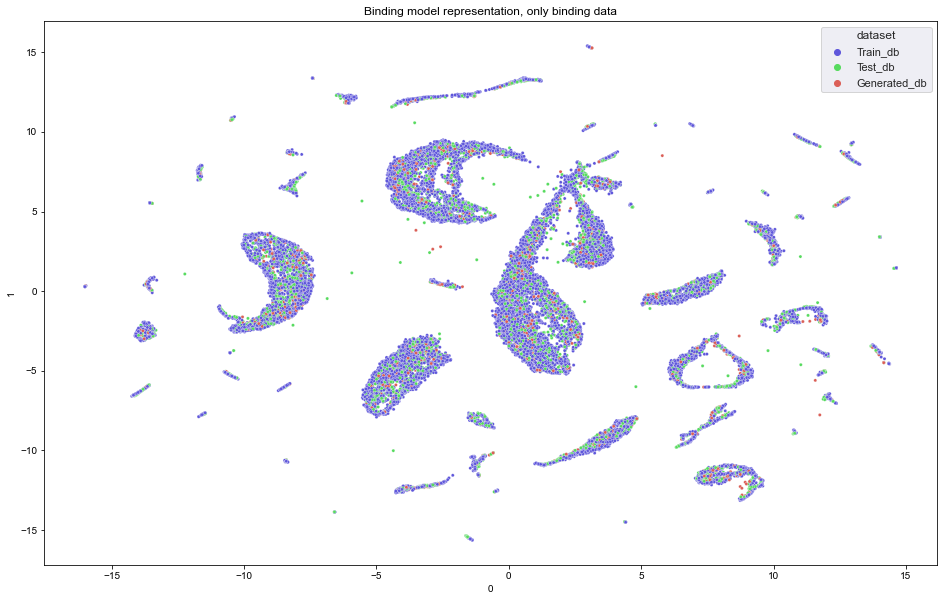

In [33]:
target_df = total_embedding_data['mb']
target_df = target_df[target_df['dataset'].str.endswith("db")]
fig = make_scatter_plot_sns(target_df, title="Binding model representation, only binding data", colors= colors)

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
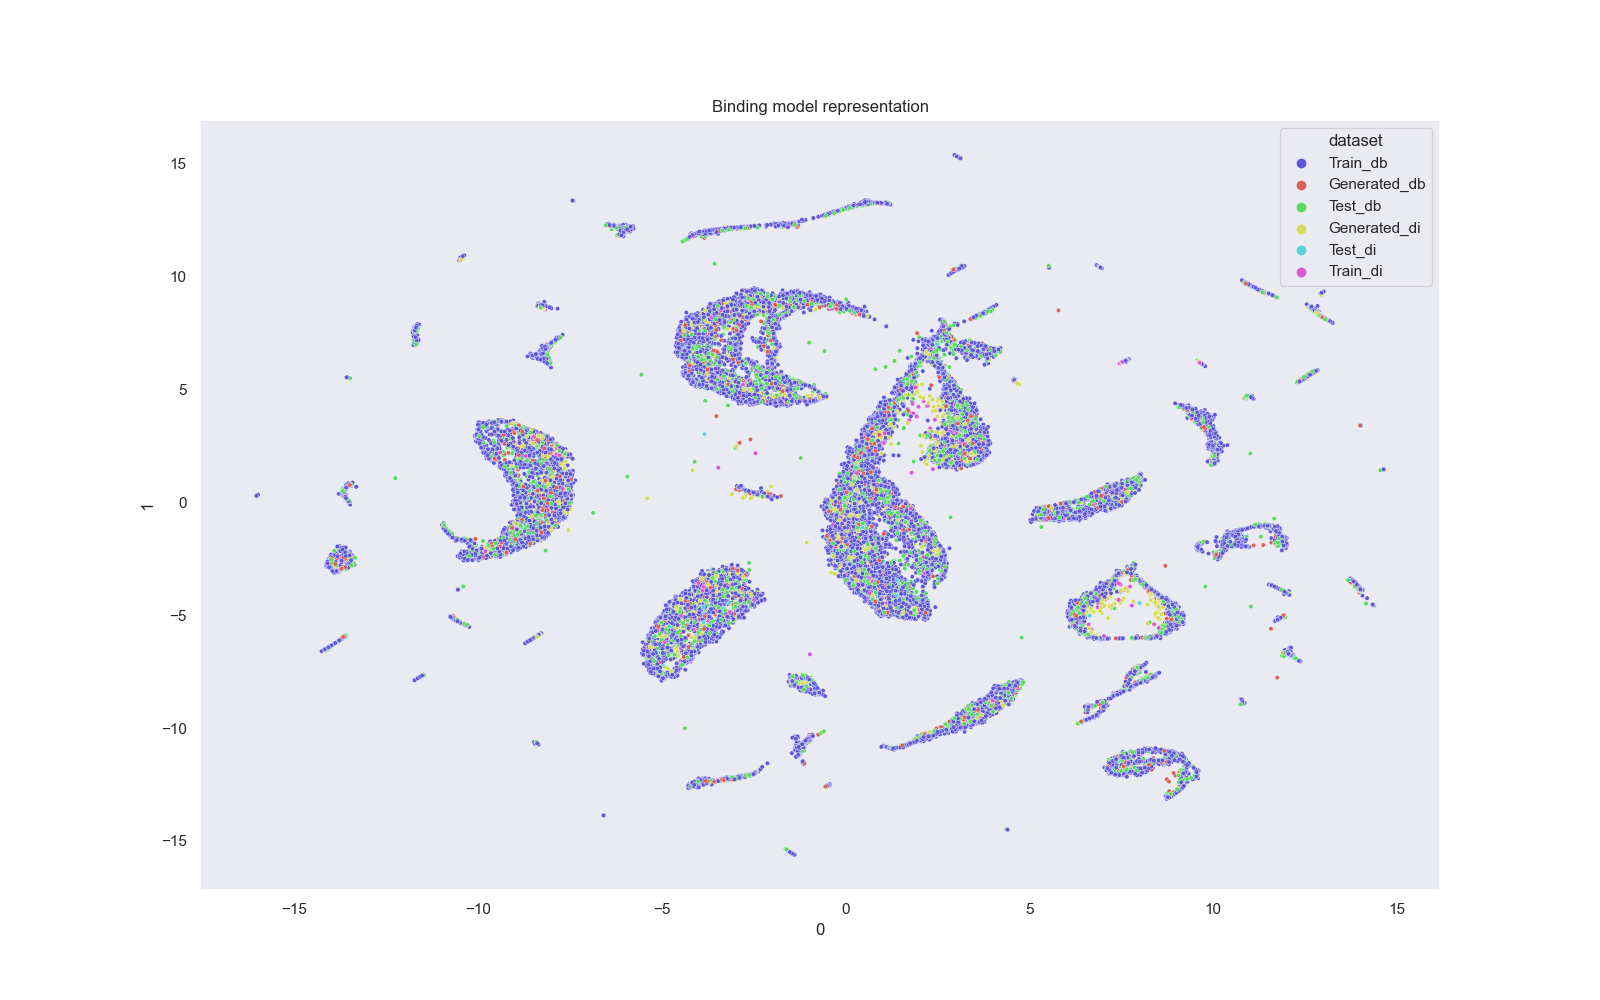

In [34]:
%matplotlib widget
# using
target_df = total_embedding_data['mb']
fig = make_scatter_plot_sns(target_df, title="Binding model representation", colors=colors)
# save_figure_to_file(fig, MODEL_PATH_USED, "umap_seaborn.png")

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
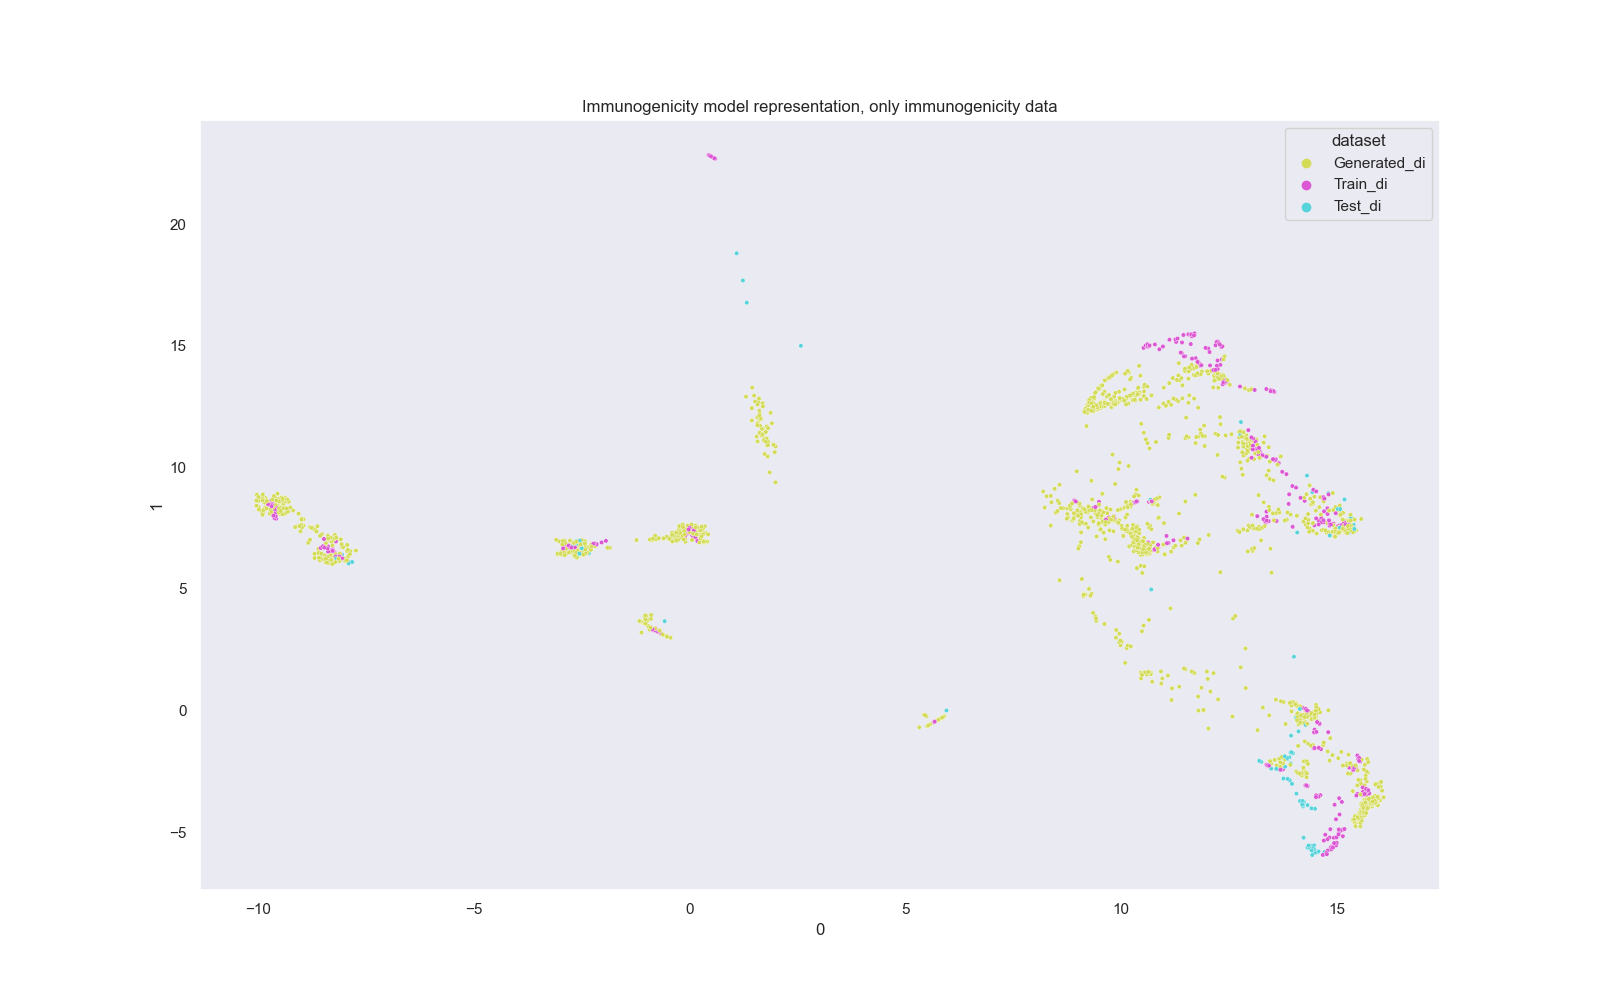

In [35]:
target_df = total_embedding_data['mi']
target_df = target_df[target_df['dataset'].str.endswith("di")]
fig = make_scatter_plot_sns(target_df, title="Immunogenicity model representation, only immunogenicity data", colors=colors)

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
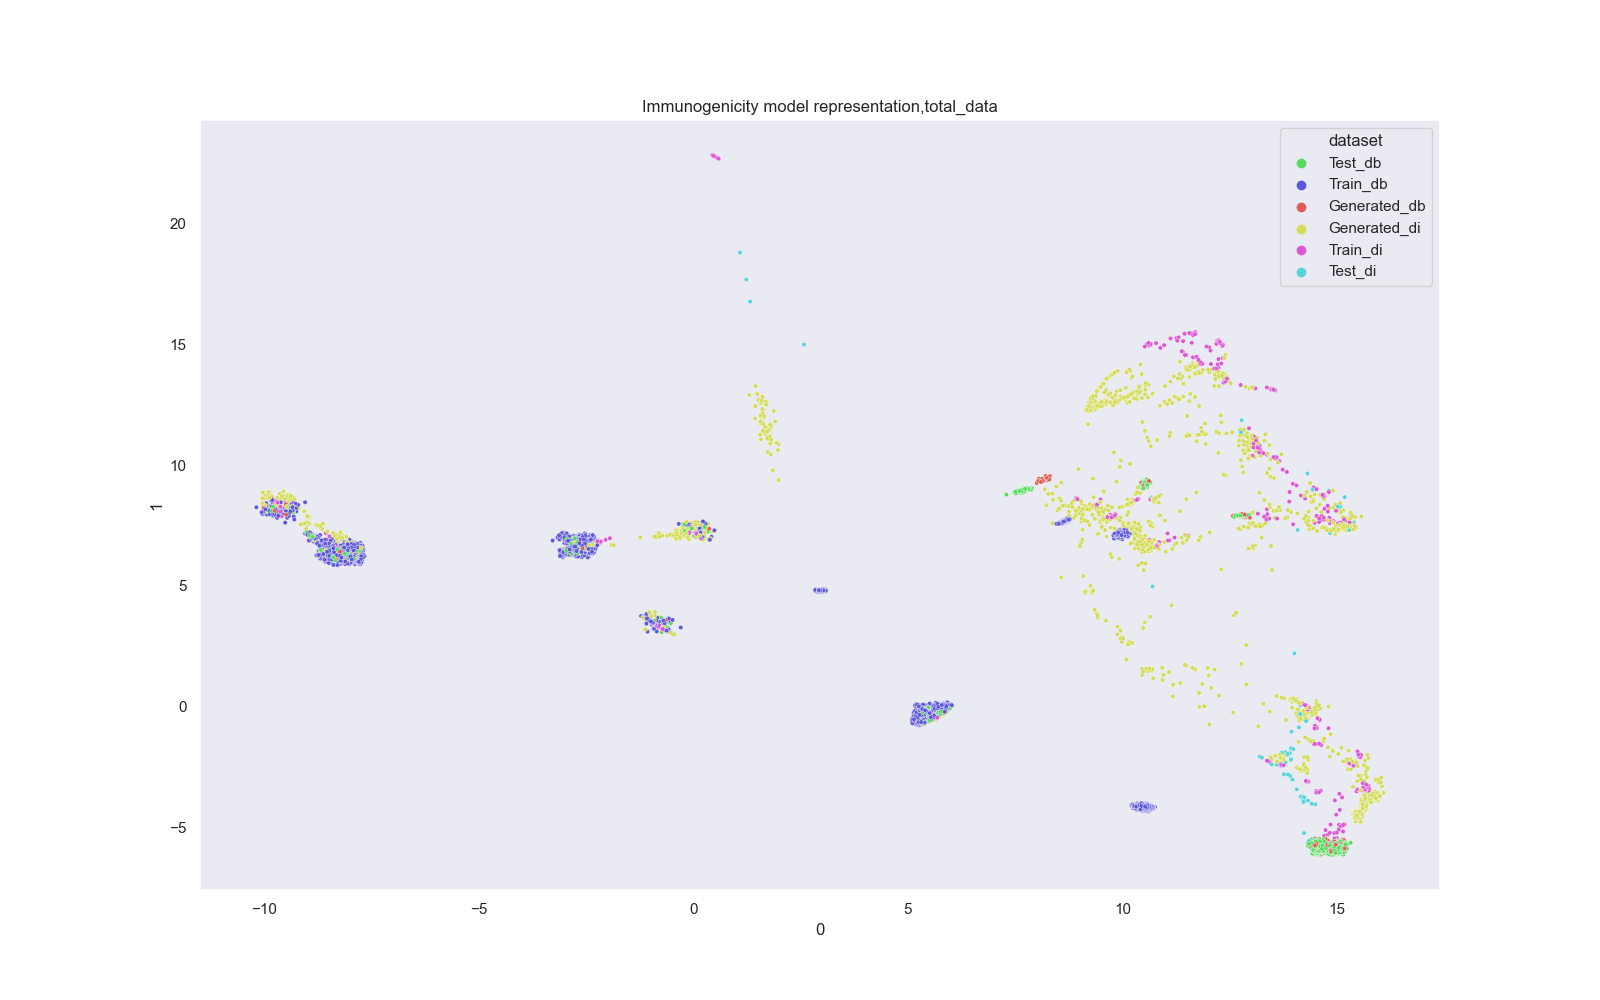

In [36]:
target_df = total_embedding_data['mi']
fig = make_scatter_plot_sns(target_df, title="Immunogenicity model representation,total_data", colors=colors)

## Cluster result image

In [37]:
#Import required module
from sklearn.cluster import KMeans

def get_k_means_result(source_df, clusters_count):
    kmeans = KMeans(n_clusters= clusters_count)
    df = source_df[[0, 1]].values
    labels = kmeans.fit_predict(df)
    unique_labels = list(set(labels))
    clustered_df = source_df.copy()
    clustered_df['label'] = labels
    return clustered_df, unique_labels

In [38]:
clustered_df_b,  unique_labels_b = get_k_means_result( total_embedding_data['mb'], 40)
clustered_df_i, unique_labels_i = get_k_means_result( total_embedding_data['mi'], 15)


In [39]:
clustered_df_b

,0,1,dataset,peptide,label
0,1.521448,-1.030514,Train_db,AAAAGRKTL,35
1,-1.660873,4.334680,Train_db,AAAAKVPEV,3
2,-8.025420,2.730108,Train_db,AAAANPLAL,2
3,0.219125,0.200817,Train_db,AAAAPRAVA,8
4,-1.363073,4.463912,Train_db,AAAAVIPTV,3
...,...,...,...,...,...
1995,2.397912,4.243464,Generated_di,YVNCYDVLA,0
1996,-3.303624,-4.492368,Generated_di,YVSEALNFA,18
1997,7.156576,0.285080,Generated_di,YVVETVHGL,14
1998,-2.820658,-4.309101,Generated_di,YVYEGLTFI,18


# Plot clusters

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
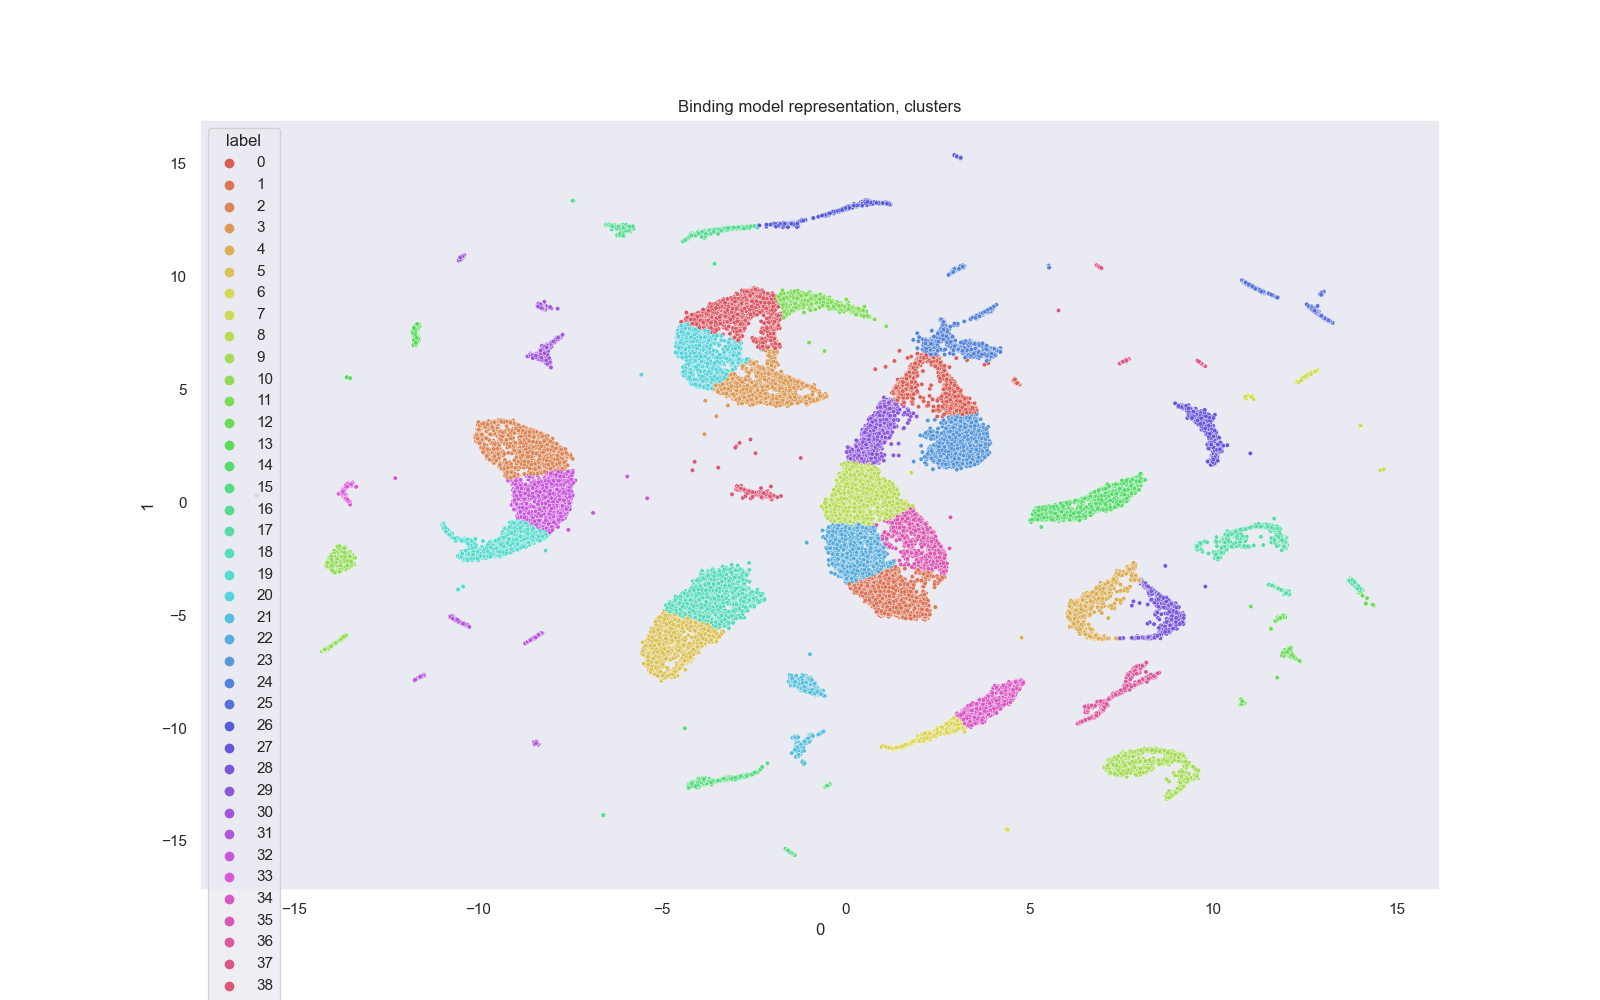

In [40]:
fig = make_scatter_plot_sns(clustered_df_b, title='Binding model representation, clusters', hue_column='label')

# save_figure_to_file(fig, MODEL_PATH_USED, "clustered_umap.png")

## Analyze clusters

In [41]:
import logomaker

def logo_pictures_for_clusters(source_clustered_df, per_dataset=False):
    if per_dataset:
        unique_datasets = set(source_clustered_df.dataset.values)
    else:
        unique_datasets = ["Whole"]
    unique_labels = set(source_clustered_df.label.values)
    fig, axes = plt.subplots(ncols=len(unique_datasets), nrows=len(unique_labels), figsize=[5*(len(unique_datasets)), 1*(len(unique_labels))])
    for cluster_index, cluster_label in enumerate(unique_labels):
        print(f" label {cluster_label}")
        for dataset_index, dataset_type in enumerate(unique_datasets):
            if per_dataset:
                print(f" label {cluster_label} dataset {dataset_type}")
                peptides = source_clustered_df[(source_clustered_df['label'] == cluster_label) & (source_clustered_df['dataset'] == dataset_type)]['peptide'].values
            else:
                peptides = source_clustered_df[source_clustered_df['label'] == cluster_label]['peptide'].values
            ax = axes[cluster_index][dataset_index] if per_dataset else axes[cluster_index]
            if len(peptides) > 0:
                matrix = logomaker.alignment_to_matrix(peptides)
                info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
                # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
                ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', ax=ax)
            ax.set_title(f"Cluster {cluster_label}, dataset {dataset_type}, size {len(peptides)}")
    plt.tight_layout()

    return fig


 label 0
 label 1
 label 2
 label 3
 label 4
 label 5
 label 6
 label 7
 label 8
 label 9
 label 10
 label 11
 label 12
 label 13
 label 14
 label 15
 label 16
 label 17
 label 18
 label 19
 label 20
 label 21
 label 22
 label 23
 label 24
 label 25
 label 26
 label 27
 label 28
 label 29
 label 30
 label 31
 label 32
 label 33
 label 34
 label 35
 label 36
 label 37
 label 38
 label 39


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
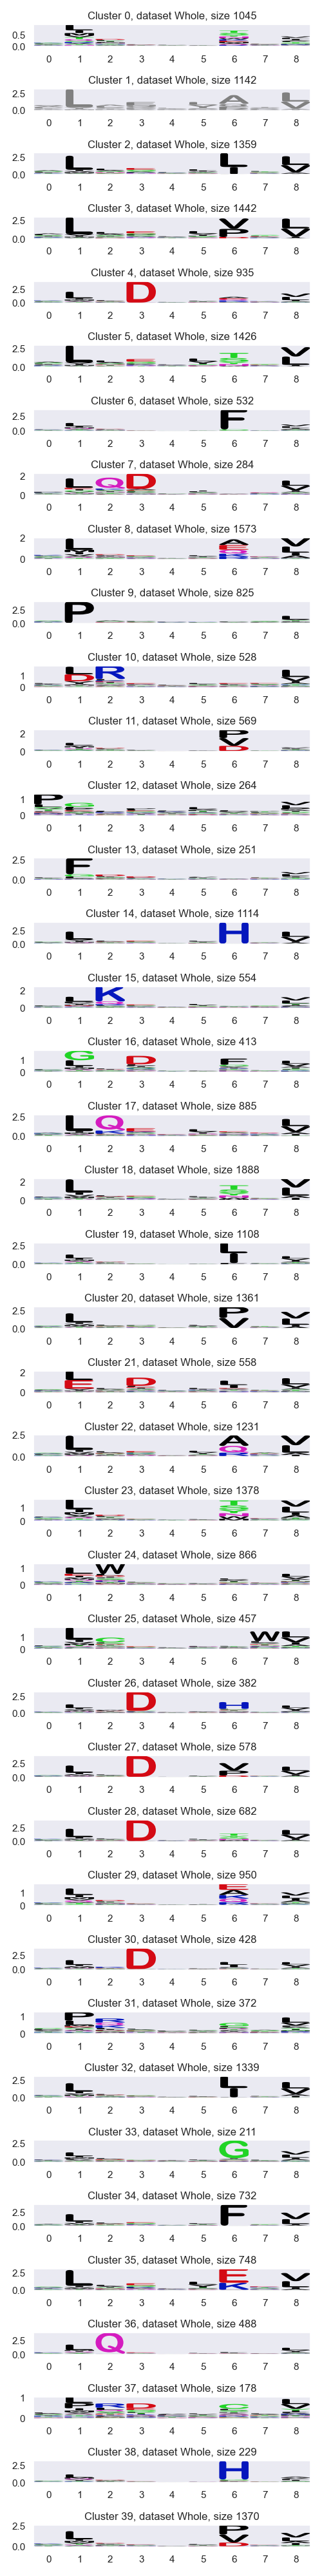

In [42]:
fig = logo_pictures_for_clusters(clustered_df_b)

In [ ]:
# if we want to plot per dataset logos (will take time for 40 clusters)
#fig = logo_pictures_for_clusters(clustered_df, per_dataset=True)


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
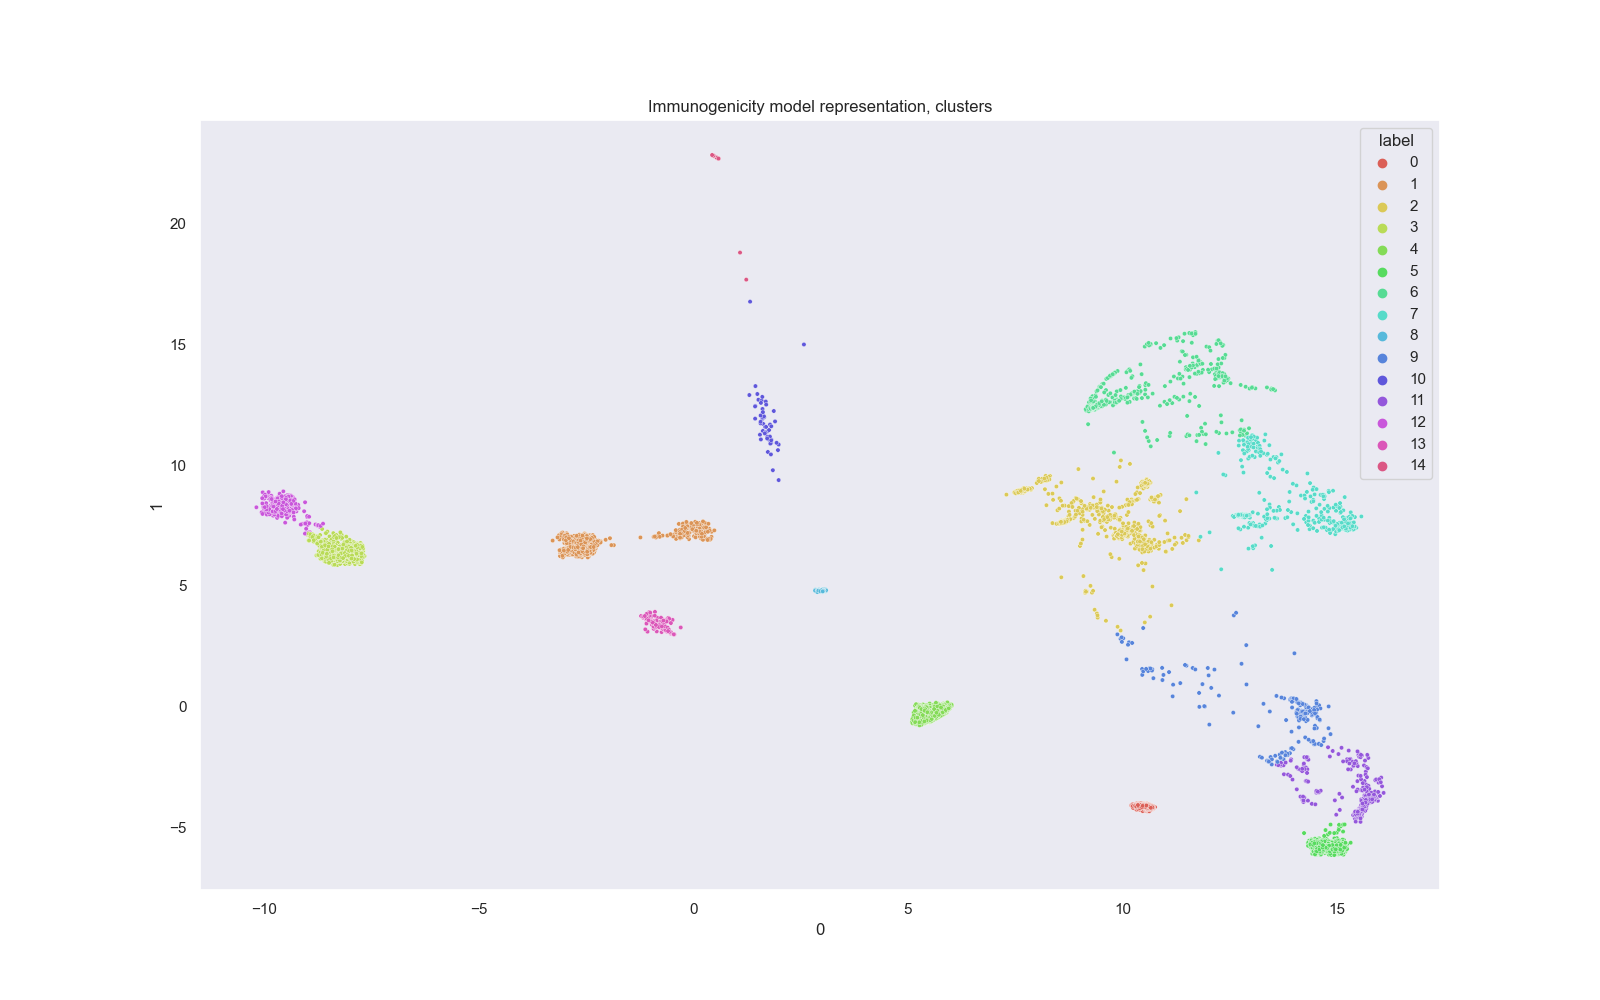

In [43]:
fig = make_scatter_plot_sns(clustered_df_i, title='Immunogenicity model representation, clusters', hue_column='label')

 label 0
 label 1
 label 2
 label 3
 label 4
 label 5
 label 6
 label 7
 label 8
 label 9
 label 10
 label 11
 label 12
 label 13
 label 14


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
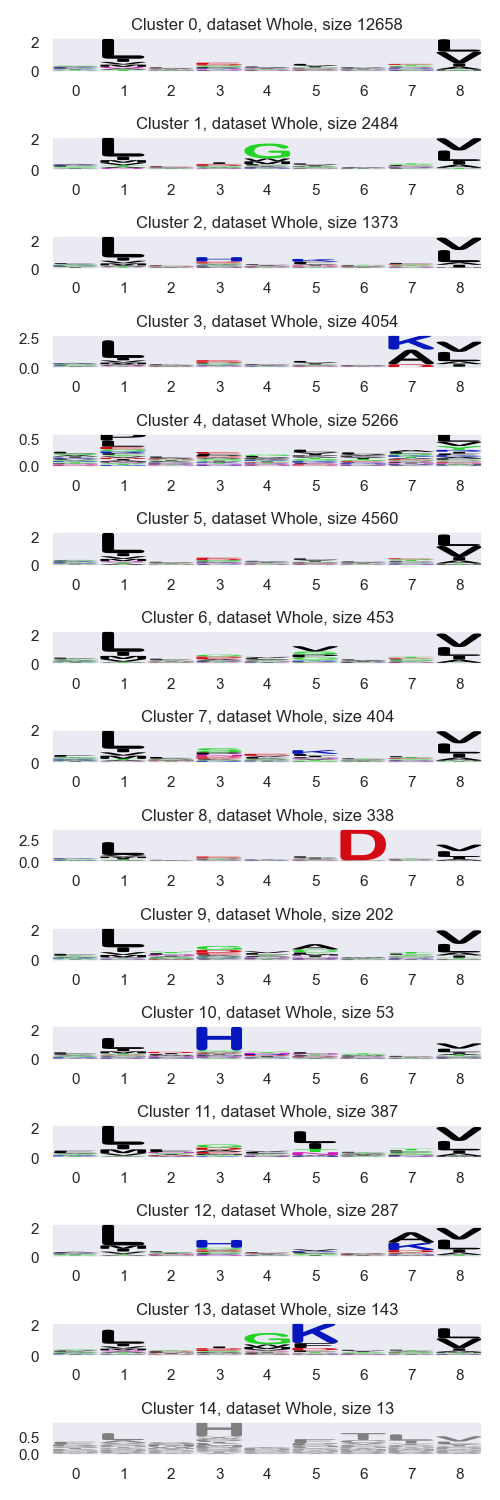

In [44]:
fig = logo_pictures_for_clusters(clustered_df_i)

# PCA

In [48]:
import sklearn
import seaborn as sns
from sklearn.decomposition import PCA


def get_pca(df_concat, n_components=2, target_col="dataset"):
    X = df_concat.drop(columns=target_col, errors='ignore').values
    pca = PCA(n_components=n_components)
    pca.fit(X)
    print('Explained variation per principal component: {}'.format(pca.explained_variance_ratio_))

    return pca

def get_pca_embedding(pca, data, target_col="dataset"):
    X = data.drop(columns=target_col, errors='ignore').values
    pca_result = pca.transform(X)
    df = pd.DataFrame(pca_result)
    return df


def collect_pca_embeddings(pivot_data_dict, pca_b, pca_i):
    embedding_dict = dict()
    for d_key in dataset_keys:
        embedding_dict[d_key] = dict()
        for s_key in source_keys:
            embedding_dict[d_key][s_key] = dict()
            embedding_dict[d_key][s_key]['mb'] =  get_pca_embedding(pca_b, pivot_data_dict[d_key][s_key]['mb'])
            embedding_dict[d_key][s_key]['mi'] =  get_pca_embedding(pca_i, pivot_data_dict[d_key][s_key]['mi'])
    return embedding_dict



In [47]:
pca_b = get_pca(pd.concat([pivot_data_dict['Train']['db']['mb']]))
pca_i = get_pca(pd.concat([pivot_data_dict['Train']['di']['mi']]))

Explained variation per principal component: [0.74719554 0.1535622 ]
Explained variation per principal component: [0.49233449 0.33703503]


In [49]:
embedding_dict = collect_pca_embeddings(pivot_data_dict, pca_b, pca_i)

In [52]:
total_embedding_data = concat_embeddings_by_data_type(pivot_data_dict, embedding_dict)

In [53]:
sample_total_embedding = total_embedding_data['mi']
sample_total_embedding

,0,1,dataset,peptide
0,98916.573145,-132081.998279,Train_db,AAAAGRKTL
1,-43707.006111,3223.989967,Train_db,AAAAKVPEV
2,129691.011375,87507.314244,Train_db,AAAANPLAL
3,-45654.516468,2166.666433,Train_db,AAAAPRAVA
4,-46756.720415,2106.155523,Train_db,AAAAVIPTV
...,...,...,...,...
1995,-46002.503391,2272.436504,Generated_di,YVNCYDVLA
1996,-46586.529811,1915.403967,Generated_di,YVSEALNFA
1997,-44646.161482,2302.773704,Generated_di,YVVETVHGL
1998,97973.198910,-133137.089099,Generated_di,YVYEGLTFI


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
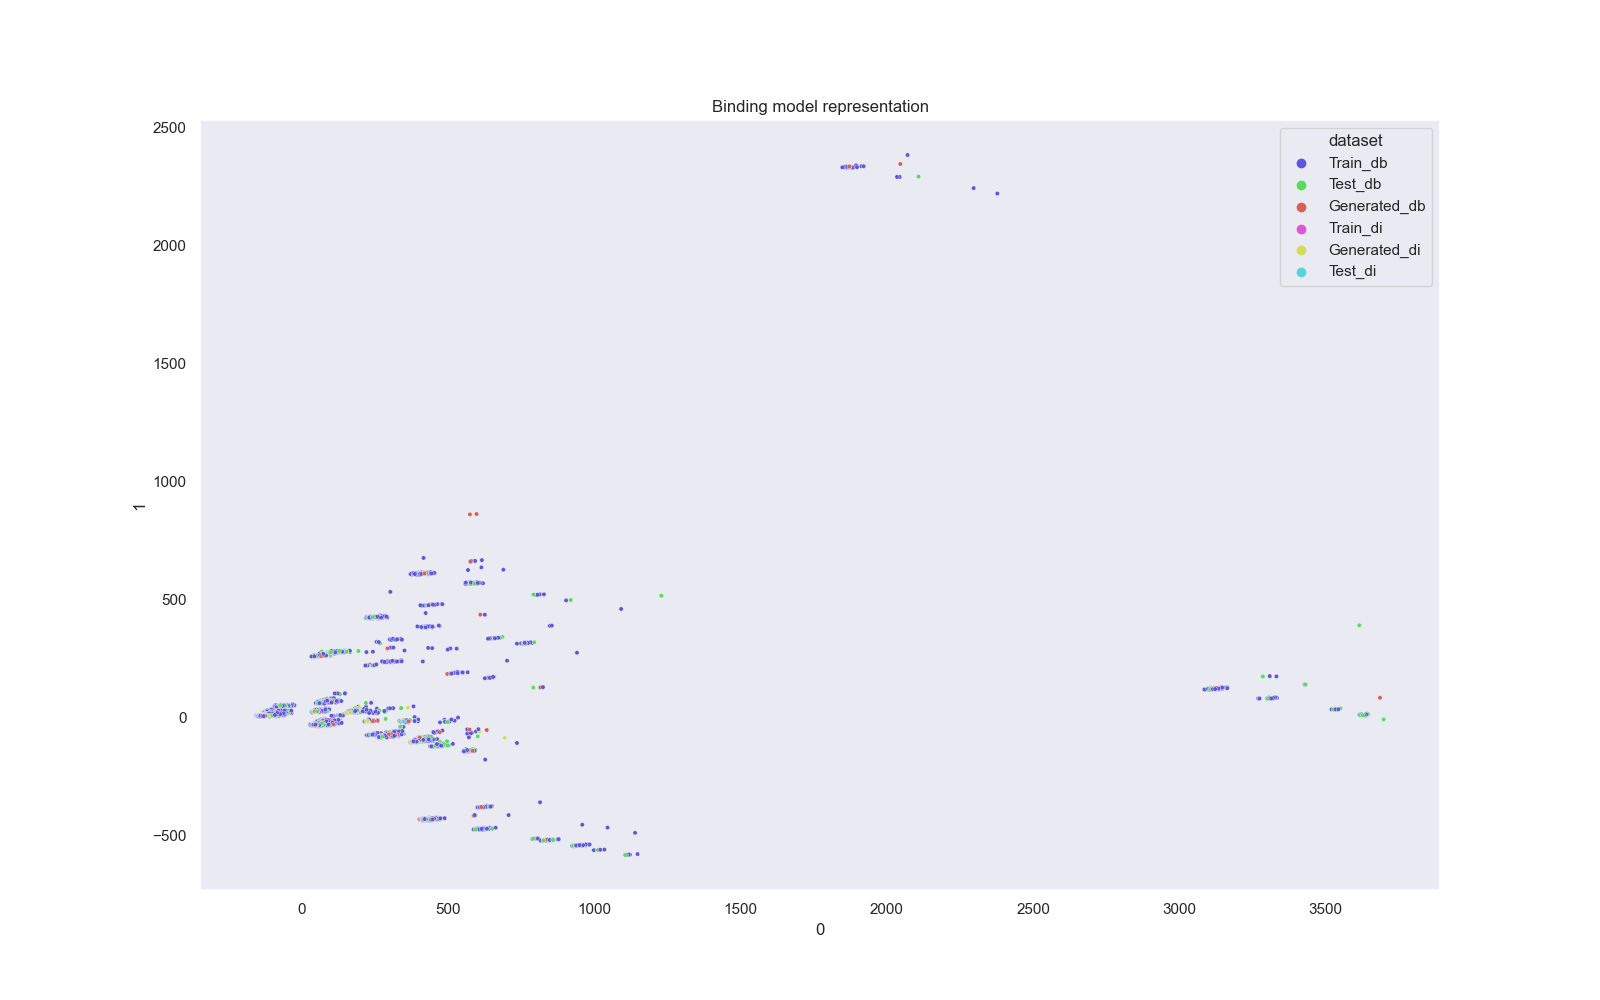

In [55]:
target_df = total_embedding_data['mb']
fig = make_scatter_plot_sns(target_df, title="Binding model representation", colors=colors)
# save_figure_to_file(fig, MODEL_PATH_USED, "umap_seaborn.png")

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
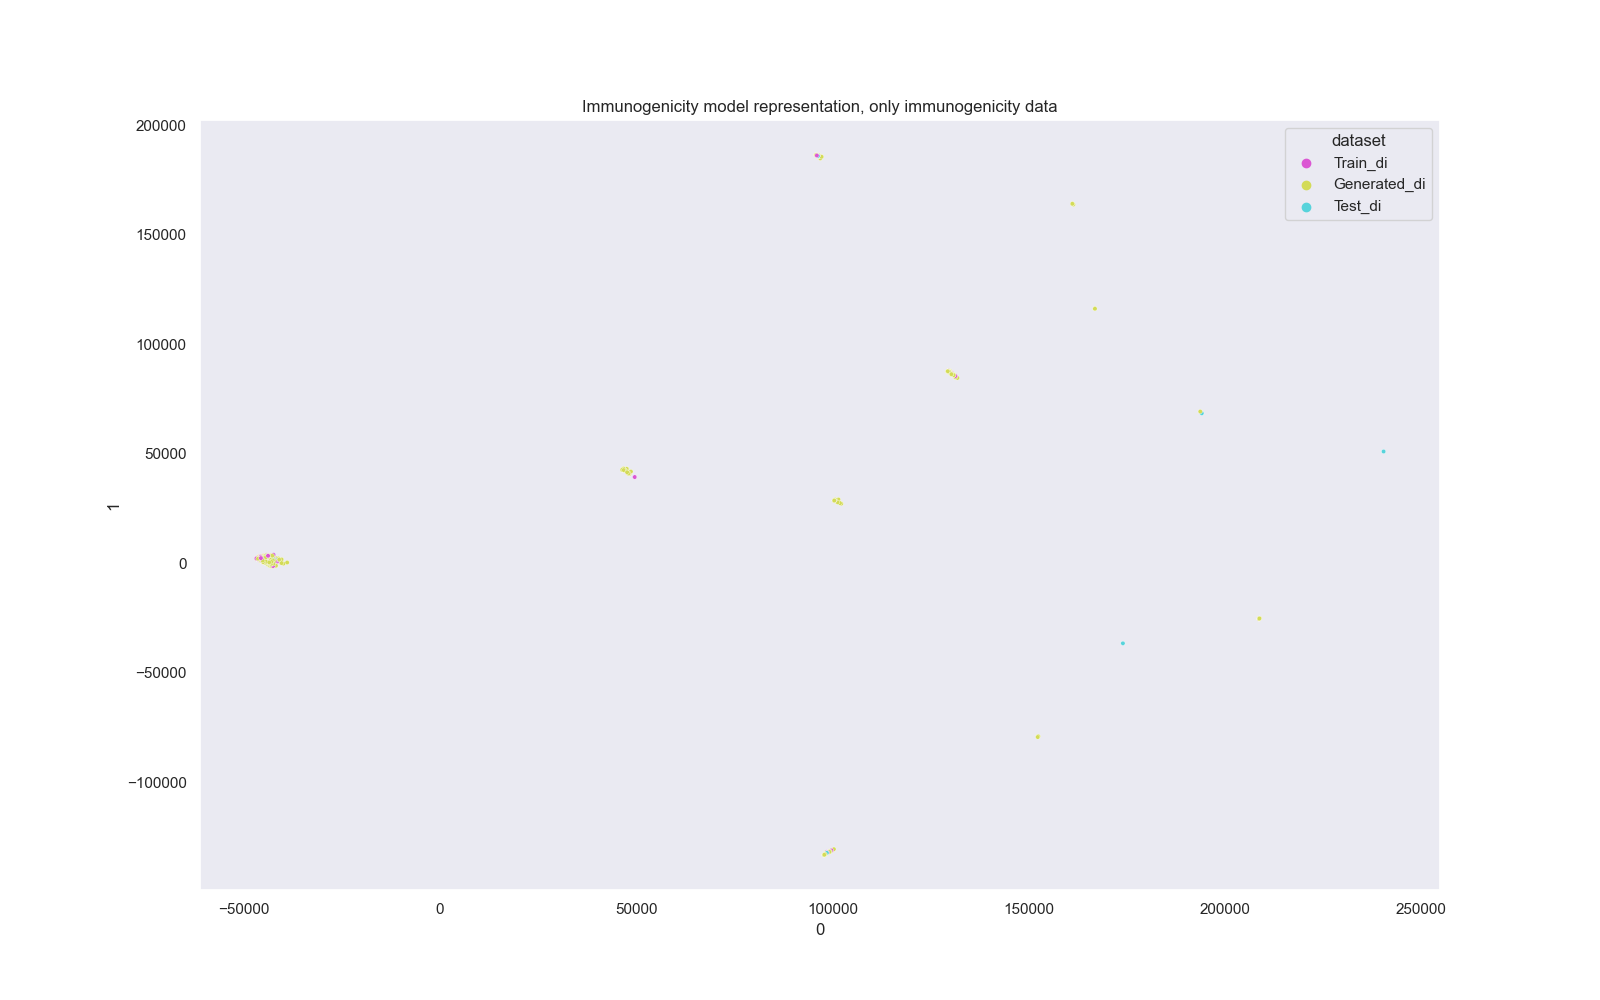

In [56]:
target_df = total_embedding_data['mi']
target_df = target_df[target_df['dataset'].str.endswith("di")]
fig = make_scatter_plot_sns(target_df, title="Immunogenicity model representation, only immunogenicity data", colors=colors)

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
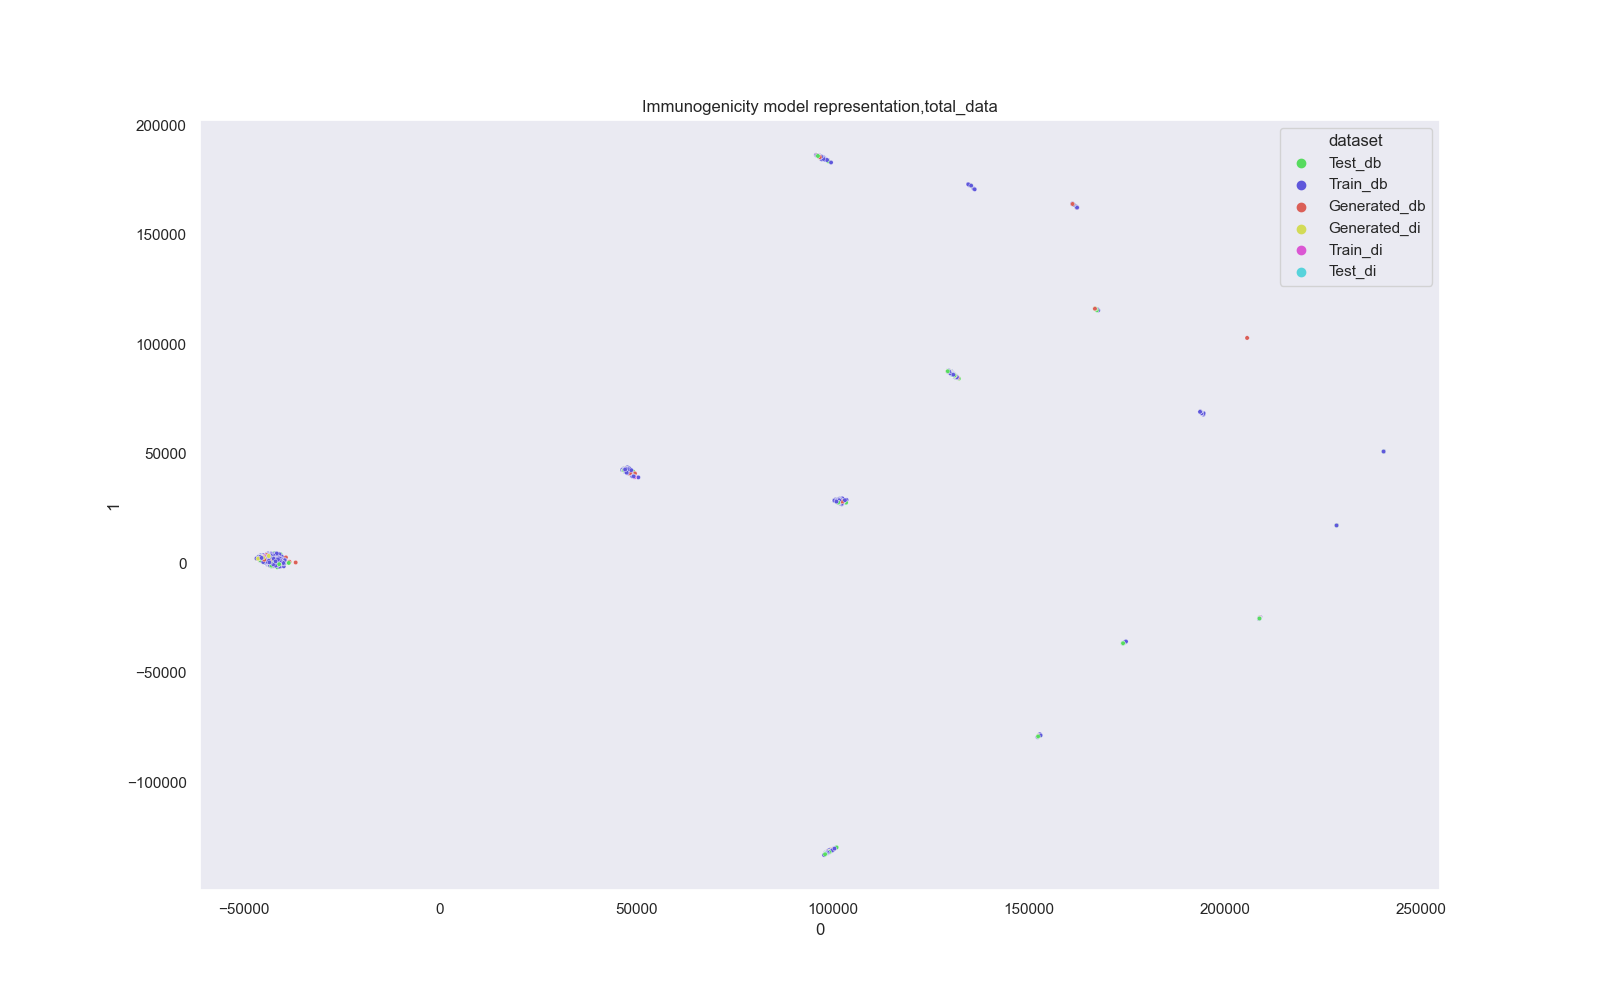

In [57]:
target_df = total_embedding_data['mi']
fig = make_scatter_plot_sns(target_df, title="Immunogenicity model representation,total_data", colors=colors)

# Skip this section for now

### Cluster PCA

In [66]:
#Import required module
from sklearn.cluster import KMeans

#Initialize the class object
kmeans = KMeans(n_clusters= 8)
df = total_df[[0, 1]].values
#predict the labels of clusters.
labels = kmeans.fit_predict(df)

unique_labels = list(set(labels))
len(labels), unique_labels

(4981, [0, 1, 2, 3, 4, 5, 6, 7])

In [67]:
clustered_df = total_df.copy()
clustered_df['label'] = labels

In [68]:
clustered_df

,0,1,dataset,peptide,label
199,-71.734416,-5.084195,Test,KLAELPAA,6
1166,-60.455292,-14.125201,Generated,LVDQSVIL,6
394,-69.179509,-1.696582,Train,FLGPIIKA,6
1316,-43.954320,-8.189019,Train,LPVKQSGV,5
1809,180.215231,338.143473,Train,RPRPGTGL,3
...,...,...,...,...,...
365,-40.319295,2.931976,Generated,FPAAQISV,5
542,-30.725554,5.885188,Train,GVVLDDPV,5
1916,10.191973,6.185996,Generated,YAEYLIRV,0
2122,-40.140821,-3.358245,Train,VIQWELSI,5


## check plot with clusters

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
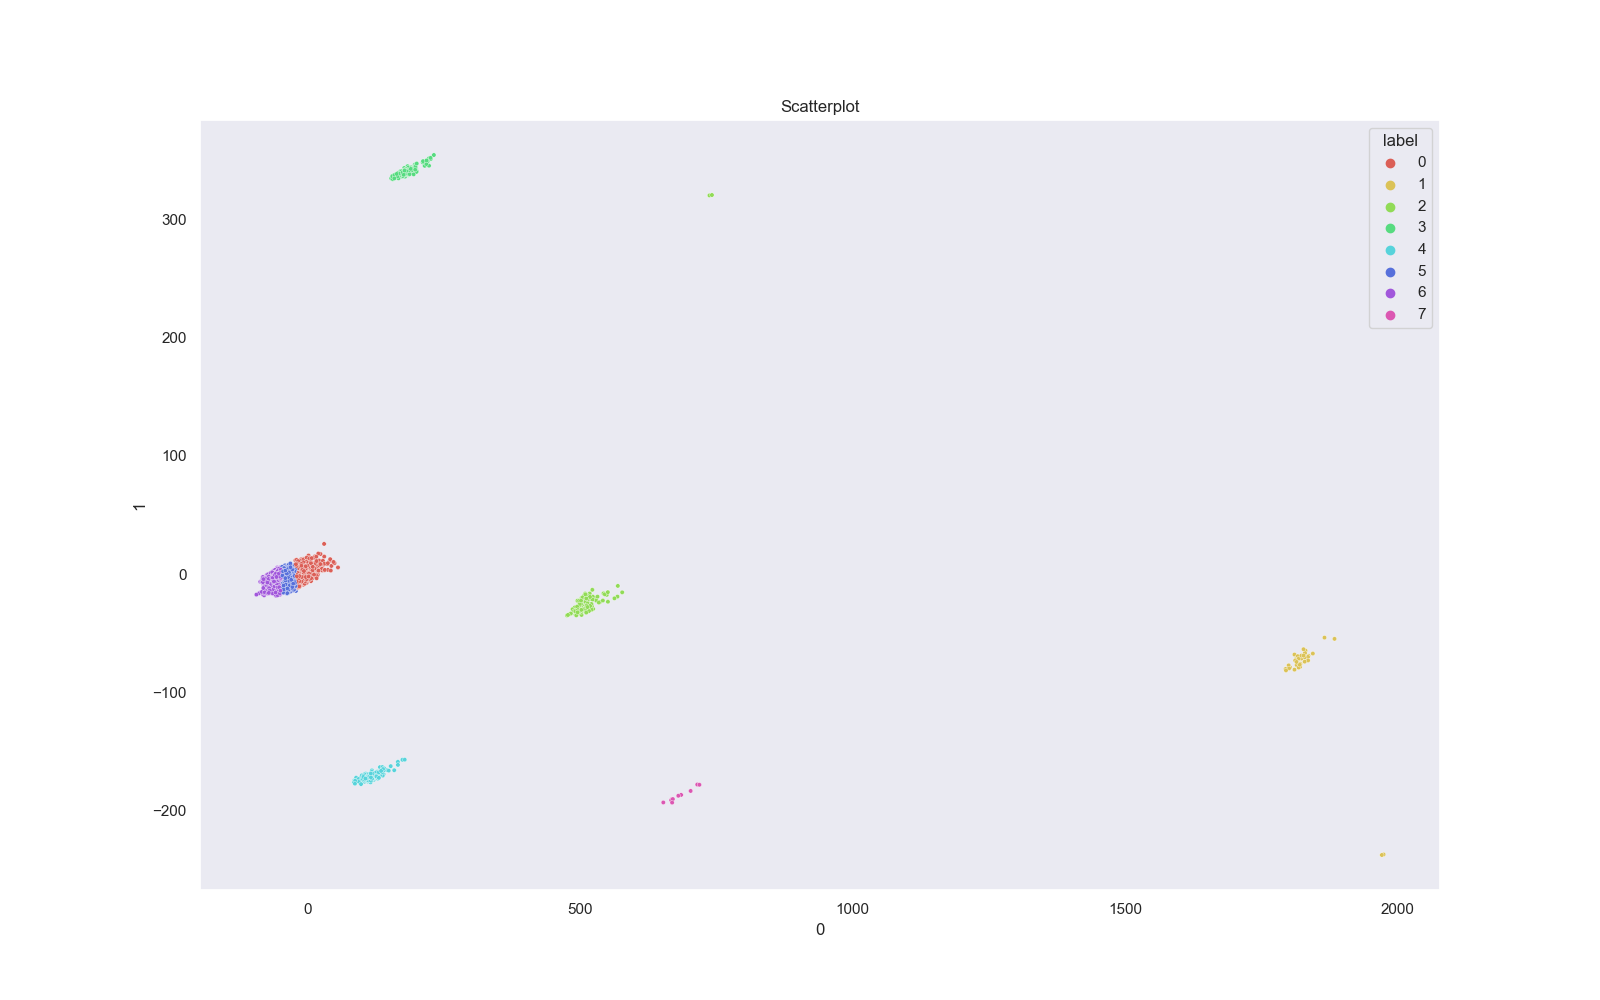

In [69]:
fig = make_scatter_plot_sns(clustered_df, hue_column='label')

save_figure_to_file(fig, MODEL_PATH_USED, "clustered_pca.png")


## Analyze clusters

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
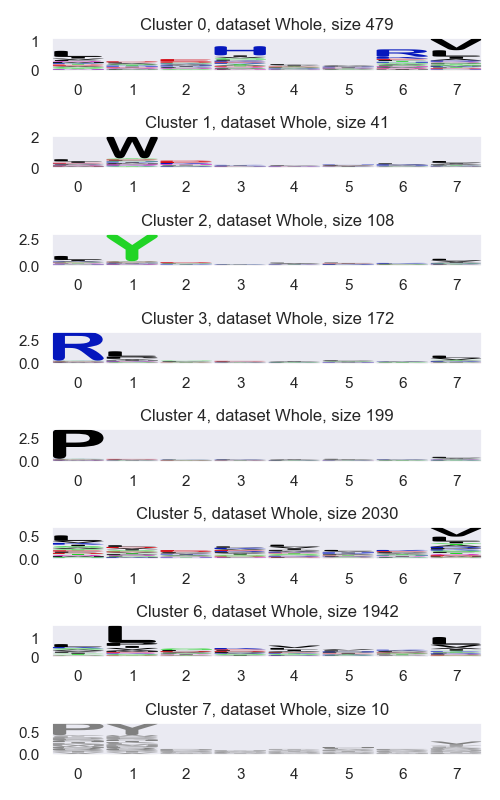

In [70]:
fig = logo_pictures_for_clusters(clustered_df)

# Cluster the original dataframe

In [92]:
pivot_data_dict['Train']['db']['mb']

path_index,0,1,2,3,4,5,6,7,8,9,...,40,41,42,43,44,45,46,47,48,49
peptide,,,,,,,,,,,,,,,,,,,,,
AAAAGRKTL,-28.799758,-26.873801,-29.137366,-25.631248,-27.769312,-30.645407,-28.719449,-28.280842,-30.482373,-26.354884,...,-32.531042,-30.050343,-26.544226,-28.682290,-28.997001,-30.605085,-31.423599,-27.917481,-30.055545,-31.260566
AAAAKVPEV,-25.569554,-22.996404,-25.082871,-27.878426,-24.716205,-27.415202,-24.842052,-25.050637,-27.252169,-22.477487,...,-29.300838,-25.995849,-28.791404,-25.629183,-25.119604,-26.727688,-27.369105,-30.164660,-27.002438,-27.206071
AAAANPLAL,-25.359990,-26.405158,-24.771510,-29.608426,-28.226757,-27.205639,-28.250807,-24.841074,-27.042605,-25.886241,...,-29.091274,-25.684487,-30.521404,-29.139735,-28.528358,-30.136442,-27.057743,-31.894659,-30.512990,-26.894710
AAAAPRAVA,-29.344312,-28.327997,-30.250030,-28.291969,-28.655397,-31.189960,-30.173645,-28.825395,-31.026927,-27.809080,...,-33.075596,-31.163008,-29.204947,-29.568374,-30.451196,-32.059280,-32.536264,-30.578203,-30.941630,-32.373230
AAAAVIPTV,-24.904557,-23.155697,-25.242164,-28.037719,-24.051208,-26.750205,-25.001345,-24.385640,-26.587172,-22.636780,...,-28.635841,-26.155142,-28.950697,-24.964186,-25.278897,-26.886981,-27.528398,-30.323953,-26.337441,-27.365364
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YYIFIPSKF,-36.559296,-35.122508,-35.723377,-36.103021,-37.191545,-37.822686,-36.385898,-33.619553,-36.588347,-32.182764,...,-41.214028,-33.292080,-33.671724,-34.760248,-32.964837,-39.777240,-34.800045,-35.179689,-36.268213,-33.565706
YYLNDLERI,-32.883258,-30.565938,-33.021655,-29.477976,-31.660659,-34.584965,-32.267645,-32.735375,-36.033117,-30.418054,...,-37.537990,-33.382218,-29.838539,-32.021222,-31.529075,-35.220670,-32.536640,-28.992961,-31.175644,-33.984793
YYNKVSTVF,-33.842061,-34.395611,-34.747780,-36.654158,-34.723011,-35.549729,-36.103278,-32.240266,-36.257327,-32.793815,...,-38.496793,-33.654431,-35.560809,-33.629661,-34.624154,-39.050343,-34.268726,-36.175104,-34.243956,-34.976324


In [68]:
def cluster_and_concat_pivot_by_data_type(pivot_dict, per_model_predictor):
    total_pivot_data_lists = defaultdict(list)
    for d_key in dataset_keys:
        for s_key in source_keys:
            for m_key in model_keys:
                representation_df = pivot_dict[d_key][s_key][m_key].copy()
                representation_df['label'] = per_model_predictor[m_key].predict(representation_df.values)
                representation_df['dataset'] = f"{d_key}_{s_key}"
                representation_df['peptide'] = representation_df.index.values
                total_pivot_data_lists[m_key].append(representation_df)
    total_pivot_data = {key:  pd.concat(total_pivot_data_lists[key]) for key in  total_pivot_data_lists}
    return total_pivot_data

In [69]:
#Import required module
from sklearn.cluster import KMeans

# train KMeans 
kmeans_b = KMeans(n_clusters= 40)
train_data = pivot_data_dict['Train']['db']['mb'].values
kmeans_b.fit(train_data)


kmeans_i = KMeans(n_clusters= 15)
train_data = pivot_data_dict['Train']['di']['mi'].values
kmeans_i.fit(train_data)


total_embedding_df = cluster_and_concat_pivot_by_data_type(pivot_data_dict, {"mb":kmeans_b , "mi": kmeans_i})

In [70]:
sample_result = total_embedding_df['mb']
sample_result

path_index,0,1,2,3,4,5,6,7,8,9,...,43,44,45,46,47,48,49,label,dataset,peptide
peptide,,,,,,,,,,,,,,,,,,,,,
AAAAGRKTL,-28.799758,-26.873801,-29.137366,-25.631248,-27.769312,-30.645407,-28.719449,-28.280842,-30.482373,-26.354884,...,-28.682290,-28.997001,-30.605085,-31.423599,-27.917481,-30.055545,-31.260566,19,Train_db,AAAAGRKTL
AAAAKVPEV,-25.569554,-22.996404,-25.082871,-27.878426,-24.716205,-27.415202,-24.842052,-25.050637,-27.252169,-22.477487,...,-25.629183,-25.119604,-26.727688,-27.369105,-30.164660,-27.002438,-27.206071,1,Train_db,AAAAKVPEV
AAAANPLAL,-25.359990,-26.405158,-24.771510,-29.608426,-28.226757,-27.205639,-28.250807,-24.841074,-27.042605,-25.886241,...,-29.139735,-28.528358,-30.136442,-27.057743,-31.894659,-30.512990,-26.894710,37,Train_db,AAAANPLAL
AAAAPRAVA,-29.344312,-28.327997,-30.250030,-28.291969,-28.655397,-31.189960,-30.173645,-28.825395,-31.026927,-27.809080,...,-29.568374,-30.451196,-32.059280,-32.536264,-30.578203,-30.941630,-32.373230,19,Train_db,AAAAPRAVA
AAAAVIPTV,-24.904557,-23.155697,-25.242164,-28.037719,-24.051208,-26.750205,-25.001345,-24.385640,-26.587172,-22.636780,...,-24.964186,-25.278897,-26.886981,-27.528398,-30.323953,-26.337441,-27.365364,1,Train_db,AAAAVIPTV
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YVNCYDVLA,-28.836251,-29.518736,-30.931735,-33.766539,-28.656371,-30.543919,-31.226404,-32.540508,-31.958370,-33.222993,...,-32.869075,-35.211780,-34.173468,-35.210327,-38.045131,-32.934964,-36.624778,27,Generated_di,YVNCYDVLA
YVSEALNFA,-24.024029,-25.528700,-26.227362,-27.147970,-24.558486,-25.953869,-27.458540,-29.120033,-28.504287,-30.624704,...,-30.162936,-32.579883,-30.183432,-30.728127,-31.648734,-29.059250,-33.278545,19,Generated_di,YVSEALNFA
YVVETVHGL,-23.578015,-23.193591,-24.328009,-32.091571,-23.676716,-25.095808,-24.711384,-28.314045,-27.646226,-27.929621,...,-28.921192,-29.832727,-27.848323,-28.416726,-36.180288,-27.765433,-30.967145,37,Generated_di,YVVETVHGL


## Make UMAP again

In [73]:
%%time
embedding_dict = collect_embeddings(pivot_data_dict, scaler_b, reducer_b, scaler_i, reducer_i )

Wall time: 9min 28s


In [74]:
%%time
total_embedding_data = concat_embeddings_by_data_type(pivot_data_dict, embedding_dict)

Wall time: 20 ms


In [77]:
for model_key in model_keys:
    total_embedding_data[model_key]['label'] = total_embedding_df[model_key]['label'].values

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
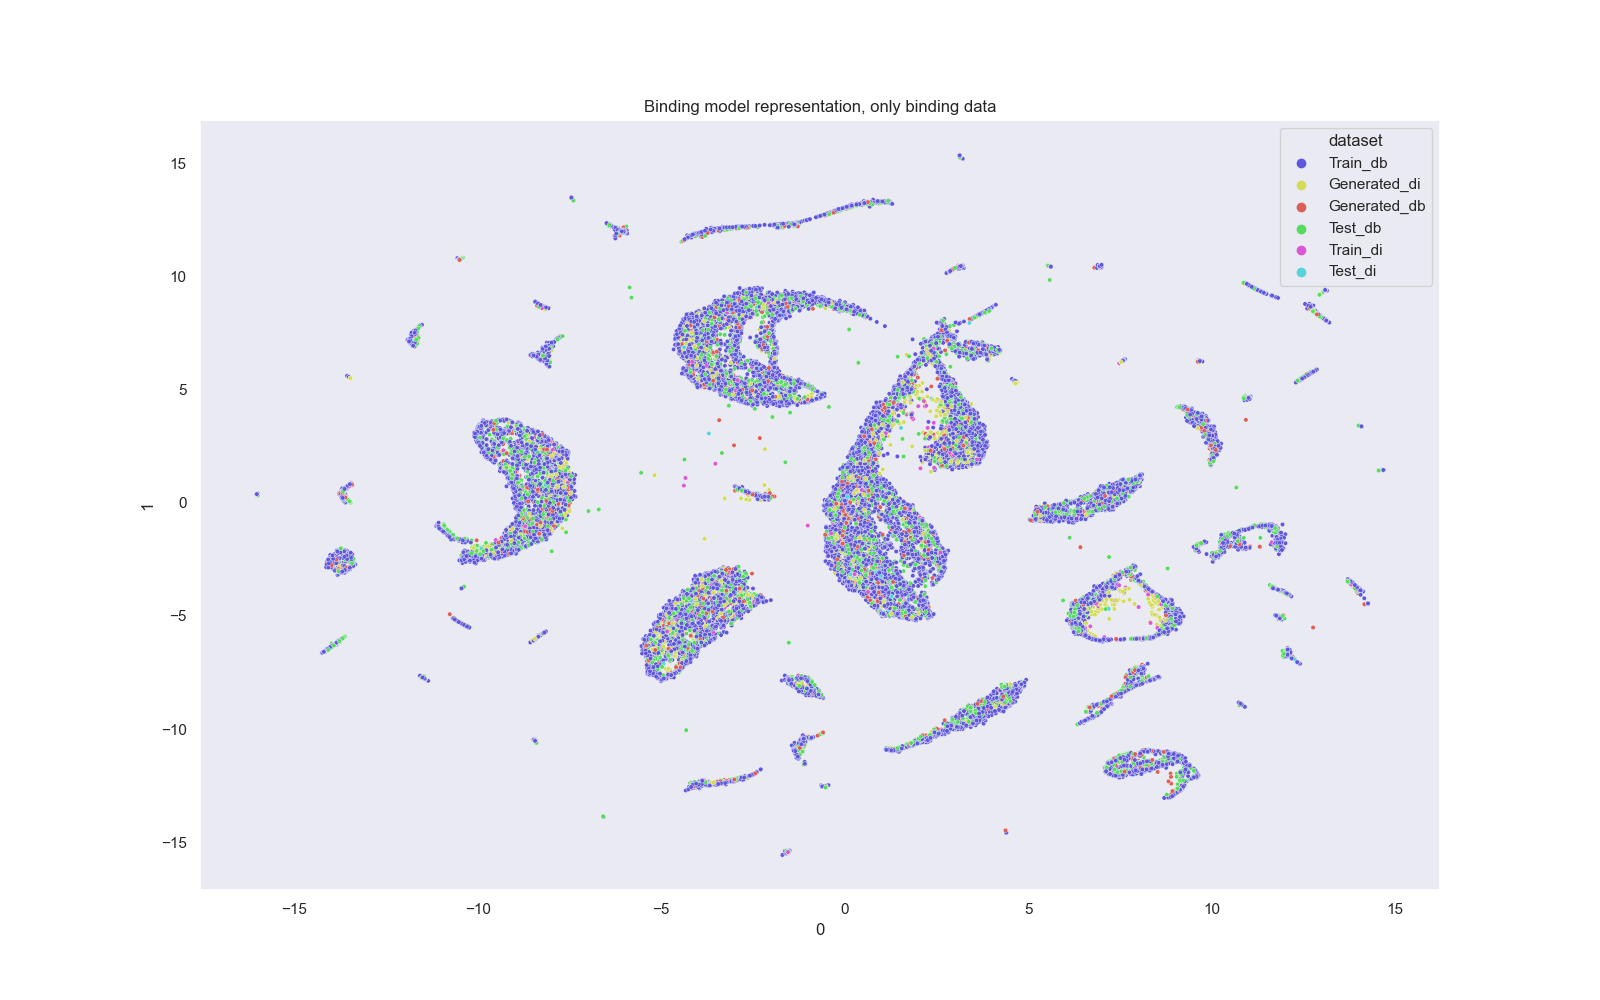

In [88]:
target_df = total_embedding_data['mb']
# target_df = target_df[target_df['dataset'].str.endswith("db")]
fig = make_scatter_plot_sns(target_df, title="Binding model representation, only binding data", colors= colors)

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
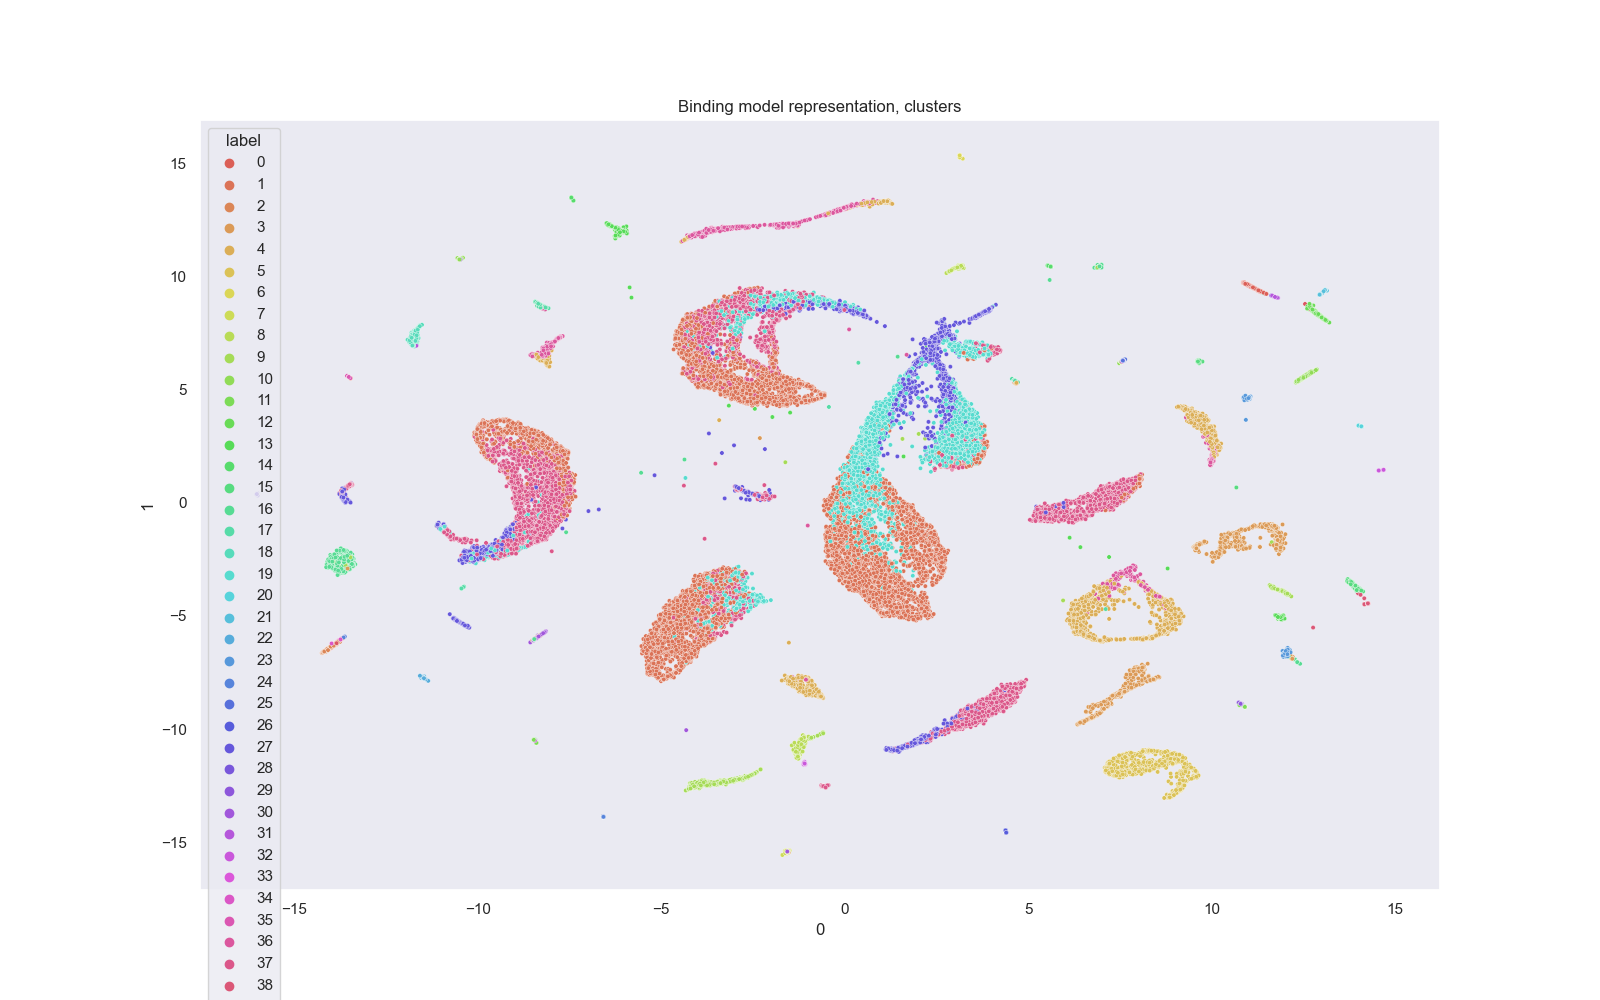

In [89]:
fig = make_scatter_plot_sns(target_df, title='Binding model representation, clusters', hue_column='label')

 label 0
 label 1
 label 2
 label 3
 label 4
 label 5
 label 6
 label 7
 label 8
 label 9
 label 10
 label 11
 label 12
 label 13
 label 14
 label 15
 label 16
 label 17
 label 18
 label 19
 label 20
 label 21
 label 22
 label 23
 label 24
 label 25
 label 26
 label 27
 label 28
 label 29
 label 30
 label 31
 label 32
 label 33
 label 34
 label 35
 label 36
 label 37
 label 38
 label 39


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
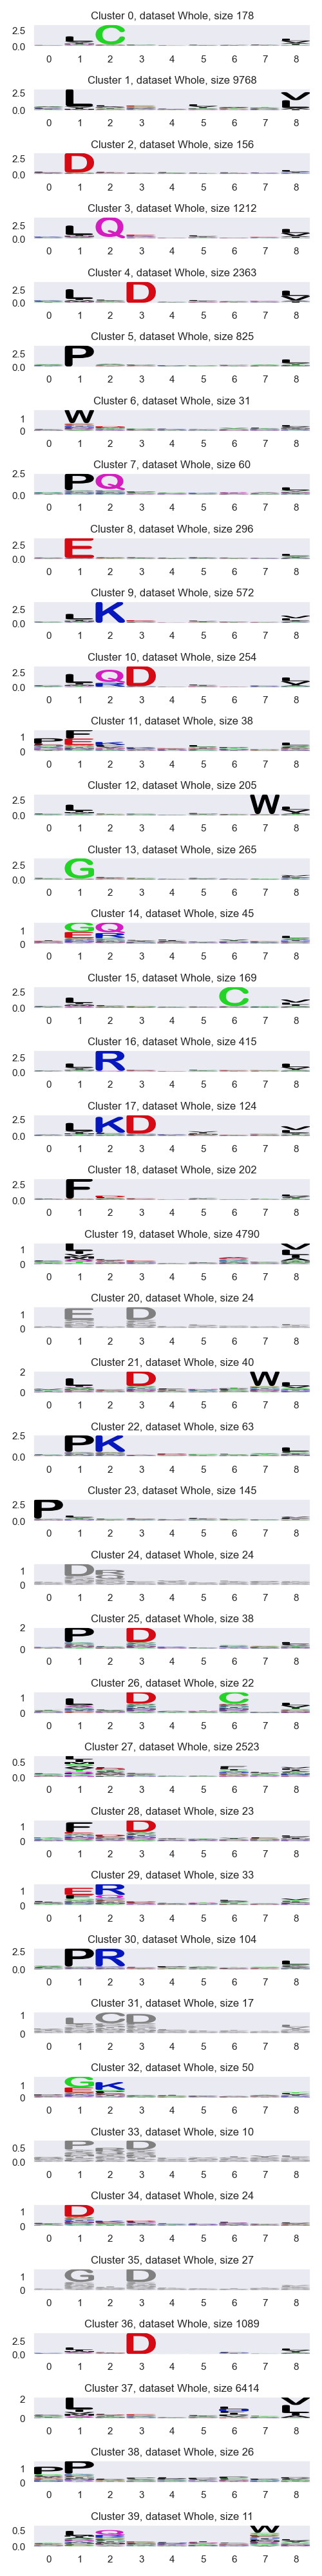

In [90]:
fig = logo_pictures_for_clusters(target_df)

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
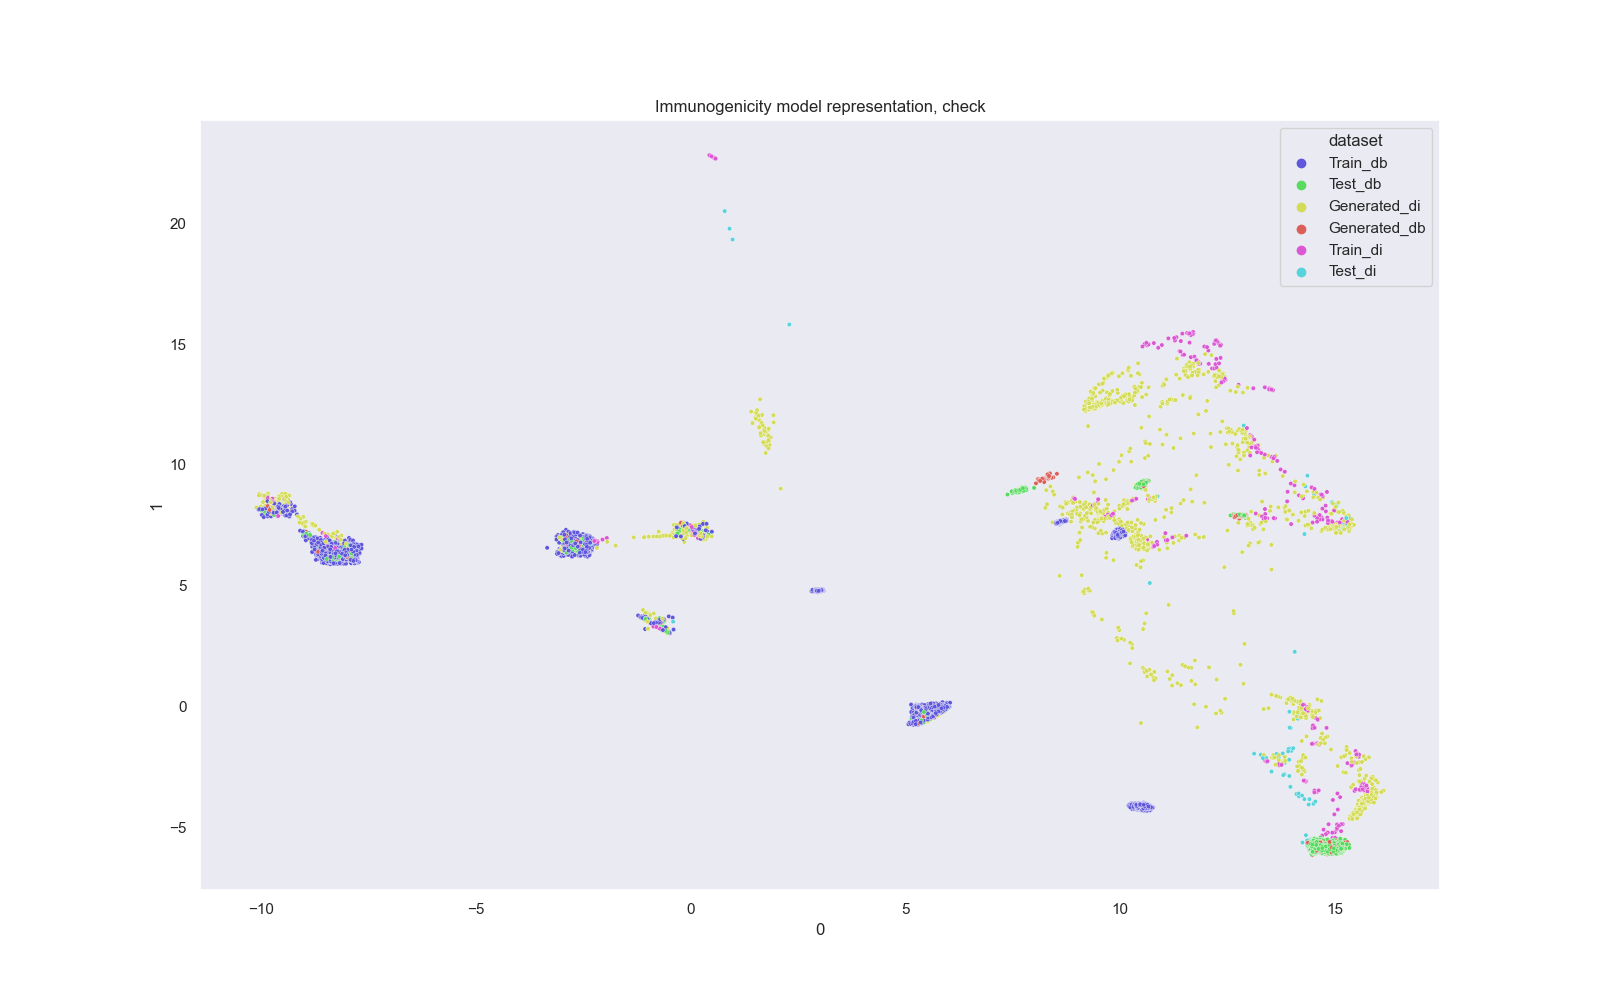

In [85]:
target_df = total_embedding_data['mi']
# target_df = target_df[target_df['dataset'].str.endswith("db")]
fig = make_scatter_plot_sns(target_df, title="Immunogenicity model representation, check", colors= colors)

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
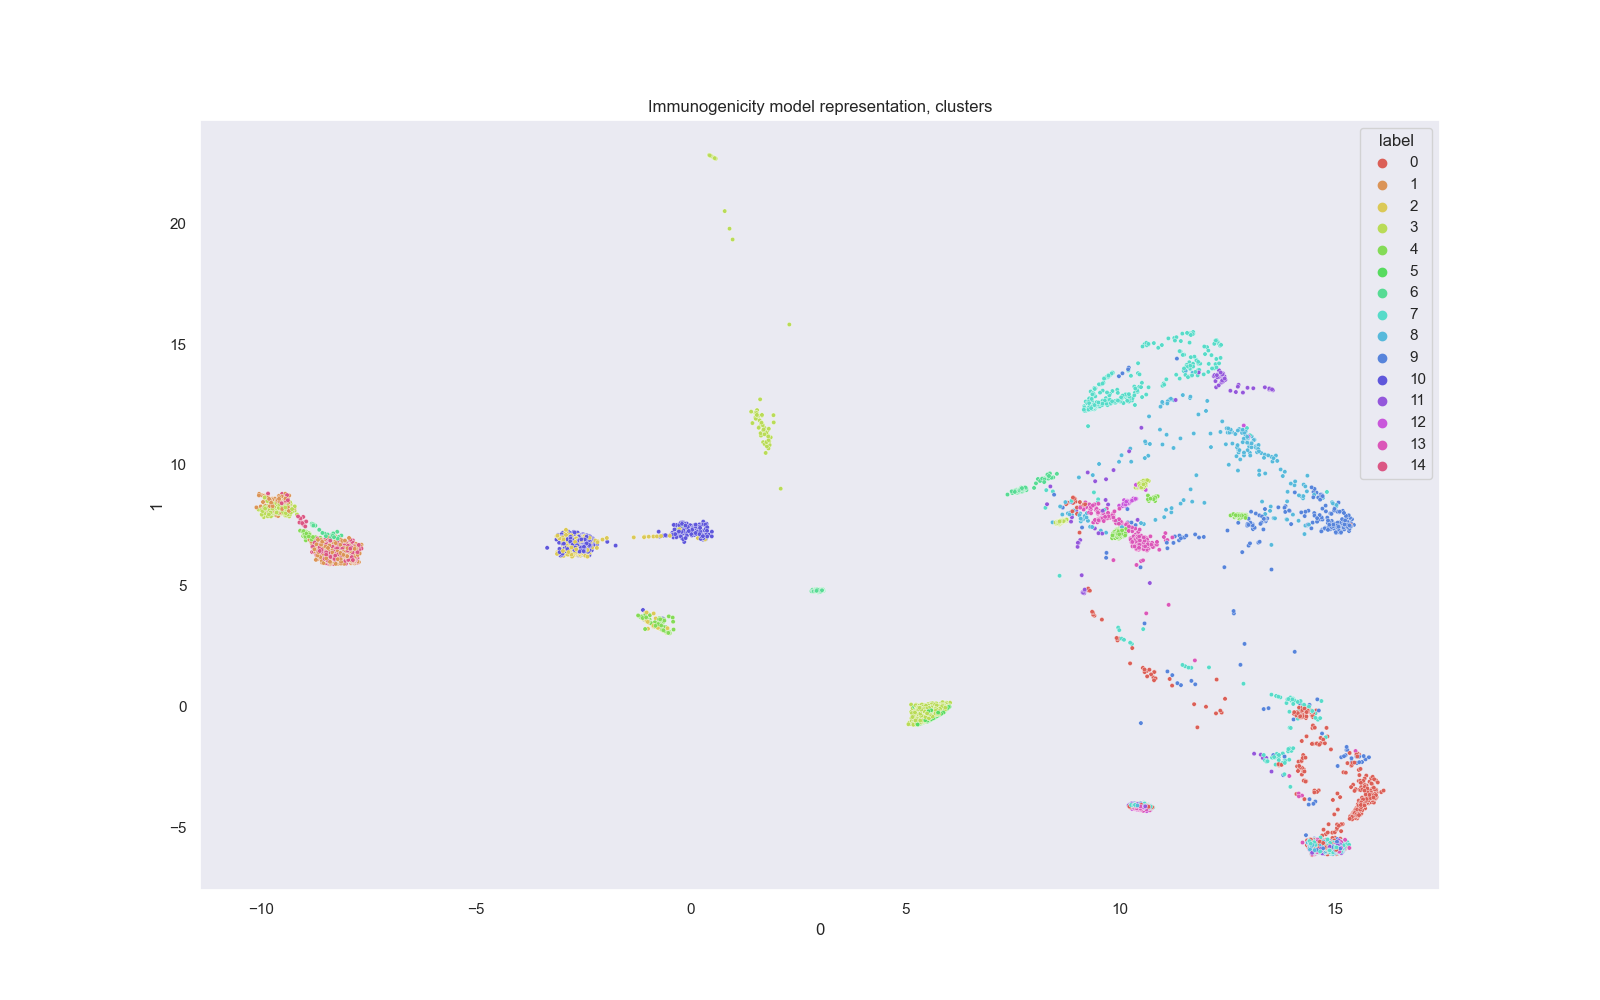

In [86]:
fig = make_scatter_plot_sns(target_df, title='Immunogenicity model representation, clusters', hue_column='label')

C:\Users\denkl\AppData\Local\Temp/ipykernel_11528/1186964750.py:9: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  fig, axes = plt.subplots(ncols=len(unique_datasets), nrows=len(unique_labels), figsize=[5*(len(unique_datasets)), 1*(len(unique_labels))])


 label 0
 label 1
 label 2
 label 3
 label 4
 label 5
 label 6
 label 7
 label 8
 label 9
 label 10
 label 11
 label 12
 label 13
 label 14


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
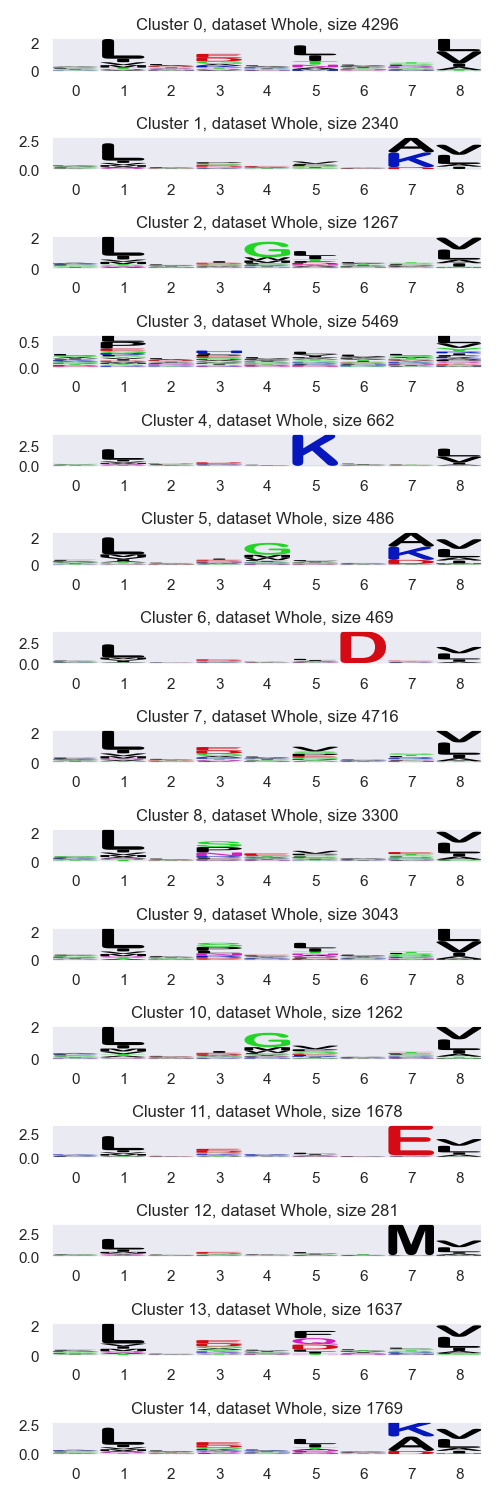

In [87]:
fig = logo_pictures_for_clusters(target_df)